In [1]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
import tensorflow as tf
from tensorflow.keras.layers import GRU, Dense, Flatten,Input, Dropout
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from tensorflow.keras.regularizers import l2
from tensorflow.keras import Model
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()
from sklearn.metrics import accuracy_score, confusion_matrix
import matplotlib.pyplot as plt
import torch
from tensorflow.keras.callbacks import ModelCheckpoint
from keras.models import load_model
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef

In [ ]:
# col_remove = ['SIP', 'DIP', 'SPort', 'DPort', 'SIT', 'STT']
# fl_mu_data=fl_mu_data.drop(col_remove, axis=1, inplace=False)
# irr_list = []
# for i in fl_mu_data:
#     if len(fl_mu_data[i].unique())<2:
#         irr_list.append(i)
# fl_mu_data=fl_mu_data.drop(irr_list, axis=1, inplace=False)

Global Server Space

In [2]:
# #Binary classification model develop by the global server
# inputs = Input(shape=(1, 73), name='input_layer')

# # GRU layer with 64 units and return sequences set to False
# gru_layer1 = GRU(64, name='gru_layer1', kernel_regularizer=l2(0.01), return_sequences=True)(inputs)

# # Dropout layer for regularization
# dropout_layer = Dropout(0.2, name='dropout_layer')(gru_layer1)

# gru_layer2 = GRU(32, name='gru_layer2', kernel_regularizer=l2(0.01), return_sequences=True)(dropout_layer)

# # Dropout layer for regularization
# dropout_layer2= Dropout(0.2, name='dropout_layer2')(gru_layer2)

# gru_layer3 = GRU(16, name='gru_layer3', kernel_regularizer=l2(0.01), return_sequences=True)(dropout_layer2)

# # Dropout layer for regularization
# dropout_layer3= Dropout(0.2, name='dropout_layer3')(gru_layer3)

# flatten_layer = Flatten(name='flatten_layer')(dropout_layer3)
# # Dense layer with 1 unit (binary classification) or more (multi-class classification)
# output_layer = Dense(2, activation='softmax', name='output_layer',kernel_regularizer=l2(0.01))(flatten_layer)

# # Build the model
# model_bin = Model(inputs=inputs, outputs=output_layer, name='GRU_Model')

# # Compile the model
# model_bin.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

# # Model summary to see the structure
# model_bin.summary()



In [15]:
# Global binary model from the server for the three clients #
G_bin_2=model_bin


SECOND CLIENT

In [4]:
cl2['category'].unique()

array([1, 3, 5, 0, 4], dtype=int64)

In [5]:
cl2['type'].unique()

array([11,  5,  3,  2,  8], dtype=int64)

In [8]:
X_C2=cl2.iloc[:,  :-3]
y_c2 = cl2.iloc[:, -3]


In [79]:
X_C2

,Unnamed: 0,FPT,LPT,FD,FAMin,FAMean,FAMax,FAStd,FIMean,FIMin,...,HTTPRM_L,HTTPRM_UL,HTTP_SCL,HTTP_SCUL:,DNSQTL,DNS_QTUL,DNS_RCL,DNS_RCUL,MQTT_MTL,MQTT_MTUL
0,0,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
1,1,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
2,2,1.723027e+09,1.723027e+09,0.341730,0.341730,0.341730,0.341730,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,1,1
3,3,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4,4,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4372247,4764390,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4372248,4764391,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4372249,4764392,1.725543e+09,1.725543e+09,0.556581,0.556581,0.556581,0.556581,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0
4372250,4764393,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.0,0.0,0.0,...,0,0,0,0,0,0,0,0,0,0


In [9]:
X_C2 = scaler.fit_transform(X_C2)

In [ ]:
X_C2=cl2.iloc[:,  :-3]
y_c2 = cl2.iloc[:, -3]
X_C2 = scaler.fit_transform(X_C2)
Xc2_train, Xc2_test, yc2_train, yc2_test = train_test_split(X_C2, y_c2, test_size=0.3, random_state=42)
Xc2_train_r = Xc2_train.reshape((Xc2_train.shape[0], 1 , Xc2_train.shape[1]))
Xc2_test_r = Xc2_test.reshape((Xc2_test.shape[0], 1 ,Xc2_test.shape[1]))

In [ ]:
from tensorflow.keras.callbacks import ModelCheckpoint
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2__best_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

In [94]:
G_bin_2=model_bin

In [17]:
G_bin_2.fit(Xc2_train_r, yc2_train, epochs=5, batch_size=32, validation_split=0.2 , callbacks=[early_stopping, checkpoint_callback])

Epoch 1/5
76508/76515 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9978 - loss: 0.1380
Epoch 1: val_loss improved from inf to 0.10694, saving model to D:/linthoi/FL_models/new/client2_binary_best_weight.keras
76515/76515 ━━━━━━━━━━━━━━━━━━━━ 216s 3ms/step - accuracy: 0.9978 - loss: 0.1380 - val_accuracy: 1.0000 - val_loss: 0.1069
Epoch 2/5
76502/76515 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9998 - loss: 0.0979
Epoch 2: val_loss improved from 0.10694 to 0.06668, saving model to D:/linthoi/FL_models/new/client2_binary_best_weight.keras
76515/76515 ━━━━━━━━━━━━━━━━━━━━ 226s 3ms/step - accuracy: 0.9998 - loss: 0.0979 - val_accuracy: 1.0000 - val_loss: 0.0667
Epoch 3/5
76491/76515 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9998 - loss: 0.0651
Epoch 3: val_loss improved from 0.06668 to 0.04795, saving model to D:/linthoi/FL_models/new/client2_binary_best_weight.keras
76515/76515 ━━━━━━━━━━━━━━━━━━━━ 237s 3ms/step - accuracy: 0.9998 - loss: 0.0650 - val_accuracy: 1.0000 - val_los

In [21]:
y2_pred_labels

array([0, 1, 1, ..., 0, 1, 1], dtype=int64)

In [3]:
X

NameError: name 'X' is not defined

In [ ]:

y2_pred = G_bin_2.predict(Xc2_test_r)  # Use the model you want (new_model or original model)
y2_pred_labels = np.argmax(y2_pred, axis=1)
# Convert the predictions to class labels (if using softmax output)
#y2_pred_labels = np.argmax(y2_pred, axis=1)

# Calculate the accuracy score


40990/40990 ━━━━━━━━━━━━━━━━━━━━ 59s 1ms/step


ValueError: Classification metrics can't handle a mix of binary and continuous-multioutput targets

Accuracy Score: 1.0


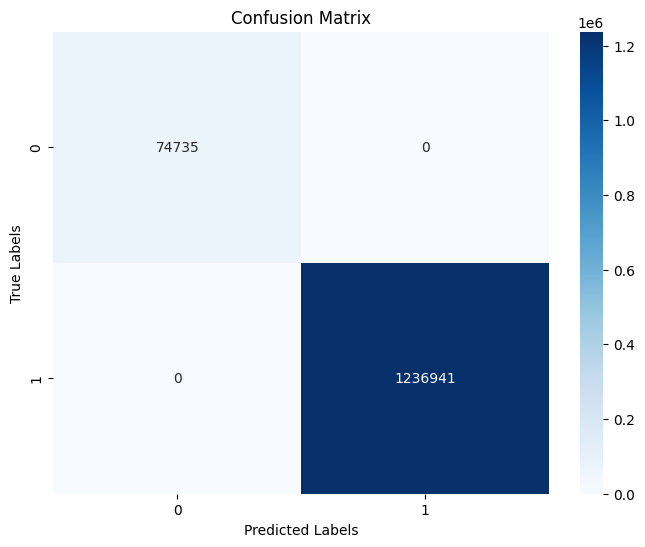

In [22]:
accuracy = accuracy_score(yc2_test, y2_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(yc2_test, y2_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(yc2_test), yticklabels=np.unique(yc2_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

In [2]:
from keras.models import load_model

In [24]:
updated_model2 = load_model('D:/linthoi/FL_models/new/1stbin_glob_model.h5')

In [27]:
updated_model2.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [26]:
updated_model2.summary()

Model: "GRU_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 1, 73)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_layer1 (GRU)                │ (None, 1, 64)          │        26,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_layer (Dropout)         │ (None, 1, 64)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_layer2 (GRU)                │ (None, 1, 32)          │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_layer2 (Dropout)        │ (None, 1, 32)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_layer3 (GRU)                │ (None, 1, 16)          │         2,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_layer3 (Dropout)        │ (None, 1, 16)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_layer (Flatten)         │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ output_layer (Dense)            │ (None, 2)              │            34 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 38,532 (150.52 KB)

 Trainable params: 38,530 (150.51 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2 (12.00 B)

In [28]:
updated_model2.fit(Xc2_train_r, yc2_train, epochs=5, batch_size=32, validation_split=0.2 , callbacks=[early_stopping, checkpoint_callback])

Epoch 1/5
76502/76515 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9993 - loss: 0.0476
Epoch 1: val_loss did not improve from 0.03452
76515/76515 ━━━━━━━━━━━━━━━━━━━━ 265s 3ms/step - accuracy: 0.9993 - loss: 0.0476 - val_accuracy: 1.0000 - val_loss: 0.0356
Epoch 2/5
76503/76515 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 0.0371
Epoch 2: val_loss improved from 0.03452 to 0.03201, saving model to D:/linthoi/FL_models/new/client2_binary_best_weight.keras
76515/76515 ━━━━━━━━━━━━━━━━━━━━ 263s 3ms/step - accuracy: 1.0000 - loss: 0.0371 - val_accuracy: 1.0000 - val_loss: 0.0320
Epoch 3/5
76513/76515 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 1.0000 - loss: 0.0333
Epoch 3: val_loss improved from 0.03201 to 0.02911, saving model to D:/linthoi/FL_models/new/client2_binary_best_weight.keras
76515/76515 ━━━━━━━━━━━━━━━━━━━━ 262s 3ms/step - accuracy: 1.0000 - loss: 0.0333 - val_accuracy: 1.0000 - val_loss: 0.0291
Epoch 4/5
76502/76515 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy

40990/40990 ━━━━━━━━━━━━━━━━━━━━ 56s 1ms/step
Accuracy Score: 1.0


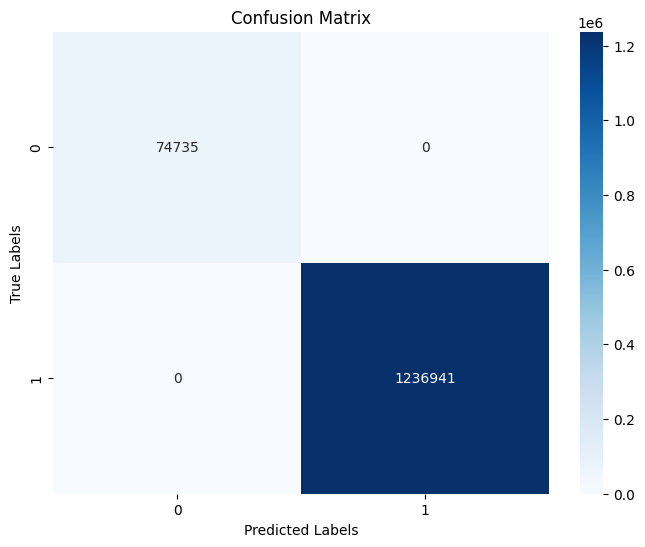

In [29]:

y2_pred = updated_model2.predict(Xc2_test_r)  # Use the model you want (new_model or original model)
y2_pred_labels = np.argmax(y2_pred, axis=1)

accuracy = accuracy_score(yc2_test, y2_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(yc2_test, y2_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(yc2_test), yticklabels=np.unique(yc2_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()

MULTICLASS CLASSIFICATION

In [6]:
cl1 = pd.read_csv("D:/linthoi/FL_splitted_data/New/Client1_data.csv")

In [7]:
cl1

,FPT,LPT,FD,FAMin,FAMean,FAMax,FAStd,FIMean,FIMin,FIMax,...,HTTP_SCUL:,DNSQTL,DNS_QTUL,DNS_RCL,DNS_RCUL,MQTT_MTL,MQTT_MTUL,label,category,type
0,1.723114e+09,1.723114e+09,0.008578,0.000065,0.002144,0.006384,0.002496,0.000254,-0.004939,0.006319,...,0,0,0,1,1,0,0,Normal,Normal,Normal
1,1.723120e+09,1.723120e+09,0.000002,0.000002,0.000002,0.000002,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,Normal,Normal,Normal
2,1.723019e+09,1.723019e+09,0.007750,0.000018,0.001937,0.005178,0.001972,0.000331,-0.003405,0.005160,...,0,0,0,1,1,0,0,Normal,Normal,Normal
3,1.723024e+09,1.723024e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,Normal,Normal,Normal
4,1.723017e+09,1.723017e+09,0.017140,0.017140,0.017140,0.017140,0.000000,0.000000,0.000000,0.000000,...,0,0,0,2,1,0,0,Normal,Normal,Normal
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1808122,1.723112e+09,1.723112e+09,0.005660,0.000010,0.001132,0.003403,0.001228,0.000149,-0.002066,0.003393,...,0,0,0,0,0,0,0,Normal,Normal,Normal
1808123,1.723029e+09,1.723029e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,Normal,Normal,Normal
1808124,1.725538e+09,1.725538e+09,0.000001,0.000001,0.000001,0.000001,0.000000,0.000000,0.000000,0.000000,...,0,2,1,0,0,0,0,attack,Sinkhole,DNS_Sinkhole
1808125,1.724835e+09,1.724835e+09,0.209092,0.000085,0.052273,0.124392,0.046853,0.021318,-0.036261,0.124307,...,0,0,0,0,0,0,0,attack,MiTM,ARP_Poisoning


In [2]:
c1=pd.read_csv(r"D:\linthoi\FL_splitted_data\iid_datas\c1.csv")
col_remove = ['SIP', 'DIP', 'SPort', 'DPort', 'SIT', 'STT']
c1=c1.drop(col_remove, axis=1, inplace=False)
irr_list = []
for i in c1:
    if len(c1[i].unique())<2:
        irr_list.append(i)
c1=c1.drop(irr_list, axis=1, inplace=False)
c1 = c1.dropna(axis=1)
c1.to_csv(r"D:\linthoi\FL_splitted_data\iid_datas\c1.csv", index=False)

In [9]:
c1

,FPT,LPT,FD,FAMin,FAMean,FAMax,FAStd,FIMean,FIMin,FIMax,...,HTTP_SCUL:,DNSQTL,DNS_QTUL,DNS_RCL,DNS_RCUL,MQTT_MTL,MQTT_MTUL,label,category,type
0,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,11
1,1.726749e+09,1.726749e+09,0.032425,0.000275,0.008106,0.012839,0.004801,-0.001513,-0.012564,0.010736,...,0,0,0,0,0,0,0,1,0,0
2,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,11
3,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,11
4,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,11
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
6264105,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,11
6264106,1.725543e+09,1.725543e+09,0.641135,0.641135,0.641135,0.641135,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,11
6264107,1.725784e+09,1.725784e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,6,10
6264108,1.725543e+09,1.725543e+09,0.518891,0.518891,0.518891,0.518891,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,11


In [3]:
from sklearn.preprocessing import LabelEncoder
label_encoder = LabelEncoder()

In [4]:
cl2['label'] = label_encoder.fit_transform(cl2['label'])
category_mapping = pd.DataFrame({
    'label': label_encoder.classes_,
    'Encoded Value': label_encoder.transform(label_encoder.classes_)
})

# Display the result
print("Original label and Encoded Values:")
print(category_mapping)


cl2['category'] = label_encoder.fit_transform(cl2['category'])
category_mapping = pd.DataFrame({
    'category': label_encoder.classes_,
    'Encoded Value': label_encoder.transform(label_encoder.classes_)
})

# Display the result
print("Original Categories and Encoded Values:")
print(category_mapping)

cl2['type'] = label_encoder.fit_transform(cl2['type'])
category_mapping = pd.DataFrame({
    'type': label_encoder.classes_,
    'Encoded Value': label_encoder.transform(label_encoder.classes_)
})

# Display the result
print("Original Categories and Encoded Values:")
print(category_mapping)

Original label and Encoded Values:
    label  Encoded Value
0  Normal              0
1  attack              1
Original Categories and Encoded Values:
               category  Encoded Value
0                  DDOS              0
1                   DoS              1
2                Normal              2
3  Selective_Forwarding              3
Original Categories and Encoded Values:
                   type  Encoded Value
0     DNS_amplification              0
1    MQTT_connect_flood              1
2                Normal              2
3  Selective_Forwarding              3
4         TCP_SYN_flood              4


In [5]:
X1=cl2.iloc[:, :-3]
y1 = cl2.iloc[:, -1]
X1 = scaler.fit_transform(X1)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, random_state=42)
X1_train_r = X1_train.reshape((X1_train.shape[0], 1 , X1_train.shape[1]))
X1_test_r = X1_test.reshape((X1_test.shape[0], 1 ,X1_test.shape[1]))

In [7]:
cl2

,FPT,LPT,FD,FAMin,FAMean,FAMax,FAStd,FIMean,FIMin,FIMax,...,HTTP_SCUL:,DNSQTL,DNS_QTUL,DNS_RCL,DNS_RCUL,MQTT_MTL,MQTT_MTUL,label,category,type
0,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,4
1,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,4
2,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,4
3,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,4
4,1.723020e+09,1.723020e+09,0.058779,0.000001,0.011756,0.056196,0.022231,0.000337,-0.054254,0.056195,...,0,0,0,0,0,0,0,0,2,2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
17251164,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,4
17251165,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,4
17251166,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,4
17251167,1.725543e+09,1.725543e+09,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0,0,0,0,0,0,0,1,1,4


In [6]:
y1.value_counts()

type
4    16158469
2     1002791
1       70703
3       17259
0        1947
Name: count, dtype: int64

In [10]:
y1.unique()

array([1, 2, 0, 3])

In [7]:
cl2['category'].unique()

array([1, 2, 0, 3])

In [ ]:
from keras.models import load_model
model_cate = load_model('D:/linthoi/FL_models/new/Cate_glob_model.h5')
model_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
from tensorflow.keras.callbacks import ModelCheckpoint
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2_cate_best_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
model_cate.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

In [13]:
from tensorflow.keras.callbacks import ModelCheckpoint
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2_cate_best_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

In [14]:
model_cate.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
301877/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9932 - loss: 0.1517
Epoch 1: val_loss improved from inf to 0.08936, saving model to D:/linthoi/FL_models/new/client2_cate_best_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 896s 3ms/step - accuracy: 0.9932 - loss: 0.1517 - val_accuracy: 0.9948 - val_loss: 0.0894
Epoch 2/10
301882/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9946 - loss: 0.0848
Epoch 2: val_loss improved from 0.08936 to 0.06791, saving model to D:/linthoi/FL_models/new/client2_cate_best_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 844s 3ms/step - accuracy: 0.9946 - loss: 0.0848 - val_accuracy: 0.9948 - val_loss: 0.0679
Epoch 3/10
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9946 - loss: 0.0702
Epoch 3: val_loss improved from 0.06791 to 0.06302, saving model to D:/linthoi/FL_models/new/client2_cate_best_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 774s 3ms/step - accuracy: 0.9946 - loss: 0.0702 - val_accuracy: 0.9948 

161730/161730 ━━━━━━━━━━━━━━━━━━━━ 239s 1ms/step
Accuracy Score: 0.994712242705857


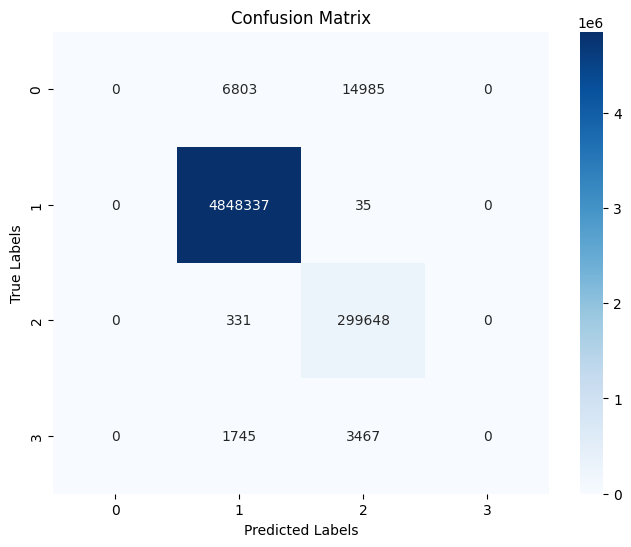

In [ ]:
y1_pred = model_cate.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef

accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification before fl: {accuracy:.4f}")
print(f"Precision for 4 class classification before fl: {precision:.4f}")
print(f"Recall for 4 class classification before fl: {recall:.4f}")
print(f"F1 Score for 4 class classification before fl: {f1:.4f}")
print(f"MCC for 4 class classification before fl: {mcc:.4f}")

In [16]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef

accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification before fl: {accuracy:.4f}")
print(f"Precision for 4 class classification before fl: {precision:.4f}")
print(f"Recall for 4 class classification before fl: {recall:.4f}")
print(f"F1 Score for 4 class classification before fl: {f1:.4f}")
print(f"MCC for 4 class classification before fl: {mcc:.4f}")

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy for 4 class classification before fl: 0.9947
Precision for 4 class classification before fl: 0.4850
Recall for 4 class classification before fl: 0.4997
F1 Score for 4 class classification before fl: 0.4922
MCC for 4 class classification before fl: 0.9551


1st fl round for category multiclass classification

In [7]:
from keras.models import load_model
model_cate = load_model('D:/linthoi/FL_models/new/1st_round_cate_glob_model.h5')
model_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
from tensorflow.keras.callbacks import ModelCheckpoint
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1_cate_after_1stround_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
model_cate.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
301877/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9946 - loss: 0.0724
Epoch 1: val_loss improved from inf to 0.06141, saving model to D:/linthoi/FL_models/new/client1_cate_after_1stround_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 813s 3ms/step - accuracy: 0.9946 - loss: 0.0724 - val_accuracy: 0.9948 - val_loss: 0.0614
Epoch 2/10
301890/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9946 - loss: 0.0633
Epoch 2: val_loss improved from 0.06141 to 0.05608, saving model to D:/linthoi/FL_models/new/client1_cate_after_1stround_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 812s 3ms/step - accuracy: 0.9946 - loss: 0.0633 - val_accuracy: 0.9947 - val_loss: 0.0561
Epoch 3/10
301891/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9942 - loss: 0.0601
Epoch 3: val_loss improved from 0.05608 to 0.05430, saving model to D:/linthoi/FL_models/new/client1_cate_after_1stround_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 789s 3ms/step - accuracy: 0.9942 - loss: 

161730/161730 ━━━━━━━━━━━━━━━━━━━━ 206s 1ms/step
Accuracy Score: 0.9947704030122788


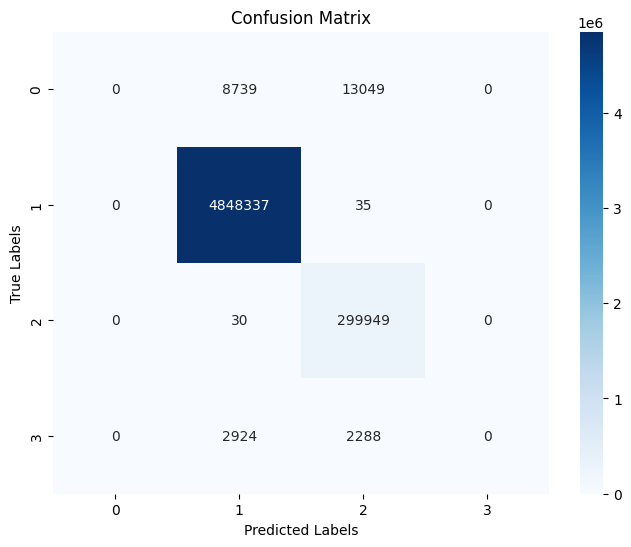

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy for 4 class classification 1st round fl: 0.9948
Precision for 4 class classification 1st round fl: 0.4872
Recall for 4 class classification 1st round fl: 0.5000
F1 Score for 4 class classification 1st round fl: 0.4934
MCC for 4 class classification 1st round fl: 0.9555


In [8]:
y1_pred = model_cate.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef

accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification 1st round fl: {accuracy:.4f}")
print(f"Precision for 4 class classification 1st round fl: {precision:.4f}")
print(f"Recall for 4 class classification 1st round fl: {recall:.4f}")
print(f"F1 Score for 4 class classification 1st round fl: {f1:.4f}")
print(f"MCC for 4 class classification 1st round fl: {mcc:.4f}")

2nd fl round 4 class classification

In [10]:
model_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/2nd_round_cate_glob_model.h5')
model_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/category/client2_cate_2ndround_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
model_cate.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9948 - loss: 0.0611
Epoch 1: val_loss improved from inf to 0.05199, saving model to D:/linthoi/FL_models/new/client2/category/client2_cate_2ndround_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 957s 3ms/step - accuracy: 0.9948 - loss: 0.0611 - val_accuracy: 0.9948 - val_loss: 0.0520
Epoch 2/10
301891/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9949 - loss: 0.0568
Epoch 2: val_loss improved from 0.05199 to 0.05018, saving model to D:/linthoi/FL_models/new/client2/category/client2_cate_2ndround_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 827s 3ms/step - accuracy: 0.9949 - loss: 0.0568 - val_accuracy: 0.9948 - val_loss: 0.0502
Epoch 3/10
301886/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9950 - loss: 0.0549
Epoch 3: val_loss improved from 0.05018 to 0.04726, saving model to D:/linthoi/FL_models/new/client2/category/client2_cate_2ndround_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 841s 3ms

Load the saved weights in .keras and set the weights to the categorical global model. This part is due to outage of current after training the model. so just predict no need for training

In [8]:
model_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/first_initialized_model/Cate_glob_model.h5')
model_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [11]:
w=tf.keras.models.load_model("D:/linthoi/FL_models/new/client2/category/client2_cate_2ndround_weight.keras")

161730/161730 ━━━━━━━━━━━━━━━━━━━━ 187s 1ms/step
Accuracy Score: 0.9947829625468881


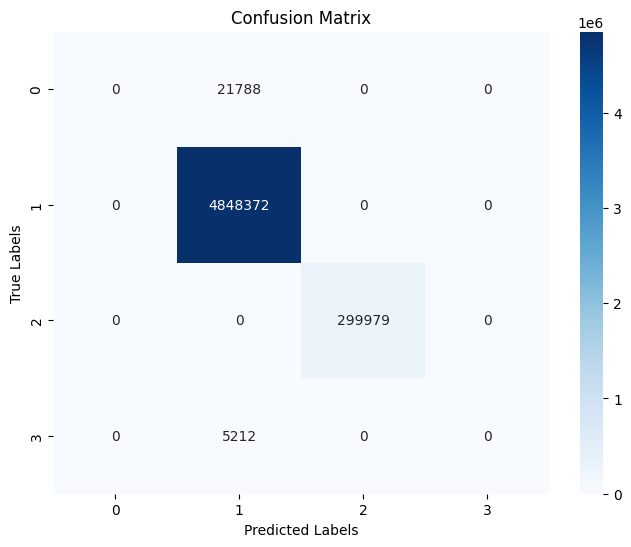

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy for 4 class classification 2nd round fl: 0.9948
Precision for 4 class classification 2nd round fl: 0.4986
Recall for 4 class classification 2nd round fl: 0.5000
F1 Score for 4 class classification 2nd round fl: 0.4993
MCC for 4 class classification 2nd round fl: 0.9554


In [15]:
y1_pred = w.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef

accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification 2nd round fl: {accuracy:.4f}")
print(f"Precision for 4 class classification 2nd round fl: {precision:.4f}")
print(f"Recall for 4 class classification 2nd round fl: {recall:.4f}")
print(f"F1 Score for 4 class classification 2nd round fl: {f1:.4f}")
print(f"MCC for 4 class classification 2nd round fl: {mcc:.4f}")

3rd fl roundm categorical classification

In [23]:
model_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/3rd_round_cate_glob_model.h5')
model_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/category/client2_cate_3rdround_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
model_cate.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
301894/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9951 - loss: 0.0544
Epoch 1: val_loss improved from inf to 0.04699, saving model to D:/linthoi/FL_models/new/client2/category/client2_cate_3rdround_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 4132s 14ms/step - accuracy: 0.9951 - loss: 0.0544 - val_accuracy: 0.9948 - val_loss: 0.0470
Epoch 2/10
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9950 - loss: 0.0530
Epoch 2: val_loss improved from 0.04699 to 0.04673, saving model to D:/linthoi/FL_models/new/client2/category/client2_cate_3rdround_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 3672s 12ms/step - accuracy: 0.9950 - loss: 0.0530 - val_accuracy: 0.9948 - val_loss: 0.0467
Epoch 3/10
301892/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9945 - loss: 0.0522
Epoch 3: val_loss did not improve from 0.04673
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 3660s 12ms/step - accuracy: 0.9945 - loss: 0.0522 - val_accuracy: 0.9948 - val_loss: 0.0489
Epoch 4

161730/161730 ━━━━━━━━━━━━━━━━━━━━ 476s 3ms/step
Accuracy Score: 0.9947686639997944


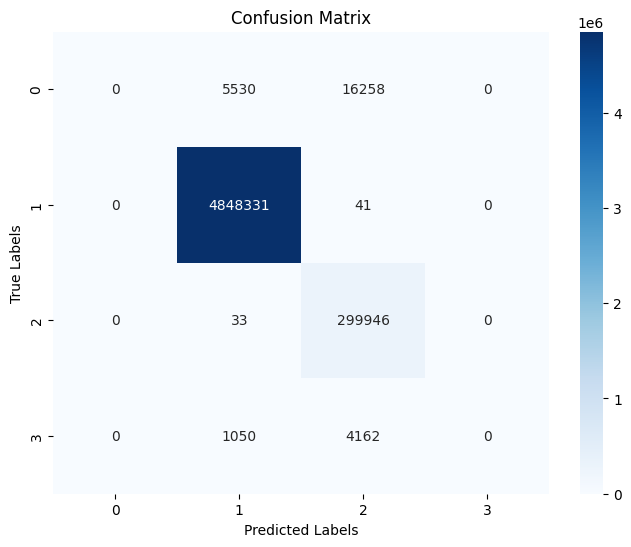

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy for 4 class classification 3rd round fl: 0.9948
Precision for 4 class classification 3rd round fl: 0.4837
Recall for 4 class classification 3rd round fl: 0.5000
F1 Score for 4 class classification 3rd round fl: 0.4916
MCC for 4 class classification 3rd round fl: 0.9557


In [24]:
y1_pred = model_cate.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef

accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification 3rd round fl: {accuracy:.4f}")
print(f"Precision for 4 class classification 3rd round fl: {precision:.4f}")
print(f"Recall for 4 class classification 3rd round fl: {recall:.4f}")
print(f"F1 Score for 4 class classification 3rd round fl: {f1:.4f}")
print(f"MCC for 4 class classification 3rd round fl: {mcc:.4f}")

5 class multiclass classification before fl (type)

In [7]:
ini_model_type = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/firstinitialized/Type_glob_model.h5')
ini_model_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_type_bforeFL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
ini_model_type.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])

Epoch 1/10
301885/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9931 - loss: 0.1539
Epoch 1: val_loss improved from inf to 0.08790, saving model to D:/linthoi/FL_models/new/client2/type/client2_type_bforeFL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 995s 3ms/step - accuracy: 0.9931 - loss: 0.1539 - val_accuracy: 0.9948 - val_loss: 0.0879
Epoch 2/10
301881/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9945 - loss: 0.0839
Epoch 2: val_loss improved from 0.08790 to 0.06743, saving model to D:/linthoi/FL_models/new/client2/type/client2_type_bforeFL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 848s 3ms/step - accuracy: 0.9945 - loss: 0.0839 - val_accuracy: 0.9948 - val_loss: 0.0674
Epoch 3/10
301884/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9945 - loss: 0.0695
Epoch 3: val_loss improved from 0.06743 to 0.06230, saving model to D:/linthoi/FL_models/new/client2/type/client2_type_bforeFL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 846s 3ms/step - accurac

161730/161730 ━━━━━━━━━━━━━━━━━━━━ 228s 1ms/step
Accuracy Score: 0.9947682775525757


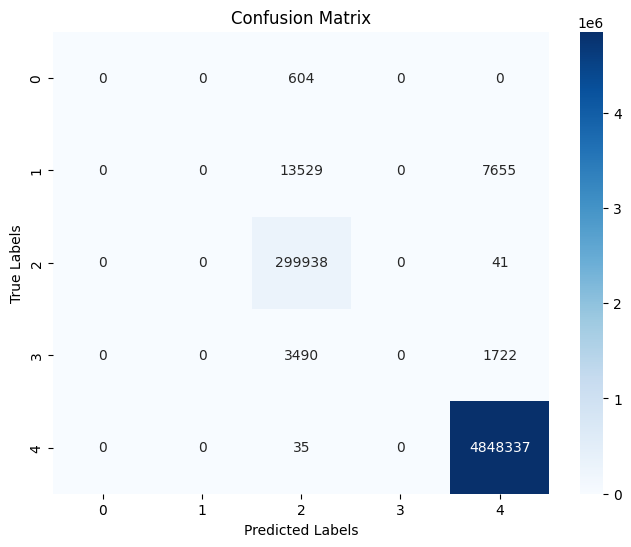

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy for 4 class classification bfore fl: 0.9948
Precision for 4 class classification bfore fl: 0.3885
Recall for 4 class classification bfore fl: 0.4000
F1 Score for 4 class classification bfore fl: 0.3941
MCC for 4 class classification bfore fl: 0.9556


In [8]:
y1_pred = ini_model_type.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
print(f"Accuracy for 4 class classification bfore fl: {accuracy:.4f}")
print(f"Precision for 4 class classification bfore fl: {precision:.4f}")
print(f"Recall for 4 class classification bfore fl: {recall:.4f}")
print(f"F1 Score for 4 class classification bfore fl: {f1:.4f}")
print(f"MCC for 4 class classification bfore fl: {mcc:.4f}")

5 class multiclass classification 1st FL round (type)

Epoch 1/10
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9366 - loss: 0.2603
Epoch 1: val_loss improved from inf to 0.25749, saving model to D:/linthoi/FL_models/new/client2/type/client2_type_1st_round_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 3419s 11ms/step - accuracy: 0.9366 - loss: 0.2603 - val_accuracy: 0.9365 - val_loss: 0.2575
Epoch 2/10
301894/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9367 - loss: 0.2571
Epoch 2: val_loss did not improve from 0.25749
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 2853s 9ms/step - accuracy: 0.9367 - loss: 0.2571 - val_accuracy: 0.9365 - val_loss: 0.2575
Epoch 3/10
301892/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9366 - loss: 0.2573
Epoch 3: val_loss improved from 0.25749 to 0.25747, saving model to D:/linthoi/FL_models/new/client2/type/client2_type_1st_round_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 2847s 9ms/step - accuracy: 0.9366 - loss: 0.2573 - val_accuracy: 0.9365 - val_loss: 0.2575
Epoch 4/10


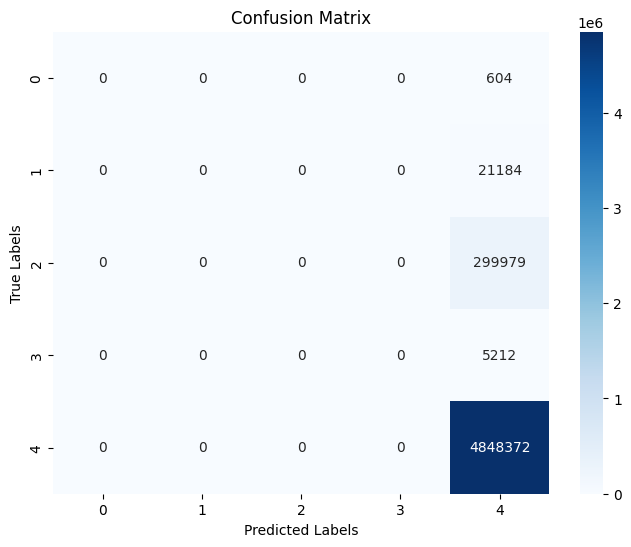

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Accuracy for 5 class classification 1st_round fl: 0.9368
Precision for 5 class classification 1st_round fl: 0.1874
Recall for 5 class classification 1st_round fl: 0.2000
F1 Score for 5 class classification 1st_round fl: 0.1935
MCC for 5 class classification 1st_round fl: 0.0000


In [9]:
model_type1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_type_glob_model.h5')
model_type1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_type_1st_round_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
model_type1.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])
y1_pred = model_type1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results


In [10]:
print(f"Accuracy for 5 class classification 1st_round fl: {accuracy:.4f}")
print(f"Precision for 5 class classification 1st_round fl: {precision:.4f}")
print(f"Recall for 5 class classification 1st_round fl: {recall:.4f}")
print(f"F1 Score for 5 class classification 1st_round fl: {f1:.4f}")
print(f"MCC for 5 class classification 1st_round fl: {mcc:.4f}")

Accuracy for 5 class classification 1st_round fl: 0.9368
Precision for 5 class classification 1st_round fl: 0.1874
Recall for 5 class classification 1st_round fl: 0.2000
F1 Score for 5 class classification 1st_round fl: 0.1935
MCC for 5 class classification 1st_round fl: 0.0000


2nd round fl 5 class multiclass classification (type)

Epoch 1/10
301894/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9942 - loss: 0.0698
Epoch 1: val_loss improved from inf to 0.05828, saving model to D:/linthoi/FL_models/new/client2/type/client2_type_2nd_round_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 572s 2ms/step - accuracy: 0.9942 - loss: 0.0698 - val_accuracy: 0.9948 - val_loss: 0.0583
Epoch 2/10
301876/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9939 - loss: 0.0619
Epoch 2: val_loss improved from 0.05828 to 0.05659, saving model to D:/linthoi/FL_models/new/client2/type/client2_type_2nd_round_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 790s 3ms/step - accuracy: 0.9939 - loss: 0.0619 - val_accuracy: 0.9946 - val_loss: 0.0566
Epoch 3/10
301887/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9939 - loss: 0.0597
Epoch 3: val_loss improved from 0.05659 to 0.05203, saving model to D:/linthoi/FL_models/new/client2/type/client2_type_2nd_round_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 1058s 4m

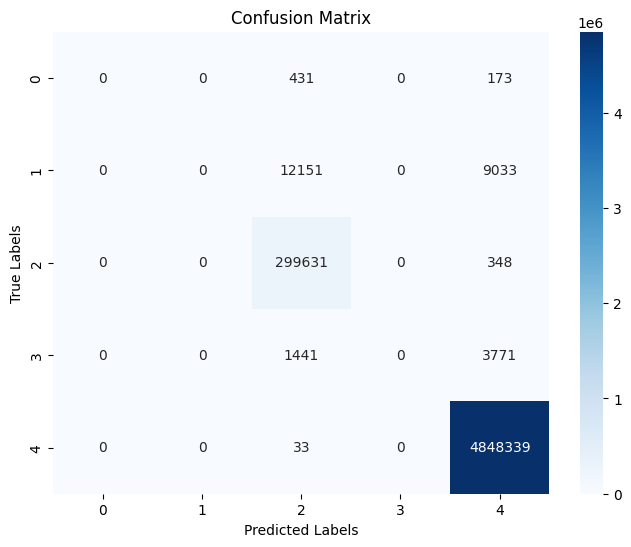

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [7]:
model_type1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_type_glob_model.h5')
model_type1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_type_2nd_round_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
model_type1.fit(X1_train_r, y1_train, epochs=10, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])
y1_pred = model_type1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results


In [8]:
print(f"Accuracy for 5 class classification 2nd_round fl: {accuracy:.4f}")
print(f"Precision for 5 class classification 2nd_round fl: {precision:.4f}")
print(f"Recall for 5 class classification 2nd_round fl: {recall:.4f}")
print(f"F1 Score for 5 class classification 2nd_round fl: {f1:.4f}")
print(f"MCC for 5 class classification 2nd_round fl: {mcc:.4f}")

Accuracy for 5 class classification 2nd_round fl: 0.9947
Precision for 5 class classification 2nd_round fl: 0.3905
Recall for 5 class classification 2nd_round fl: 0.3998
F1 Score for 5 class classification 2nd_round fl: 0.3950
MCC for 5 class classification 2nd_round fl: 0.9549


3rd round (type)

Epoch 1/5
301894/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.9941 - loss: 0.0611
Epoch 1: val_loss improved from inf to 0.05155, saving model to D:/linthoi/FL_models/new/client2/type/client2_type_3rd_round_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 2848s 9ms/step - accuracy: 0.9941 - loss: 0.0611 - val_accuracy: 0.9947 - val_loss: 0.0516
Epoch 2/5
301892/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9939 - loss: 0.0575
Epoch 2: val_loss improved from 0.05155 to 0.05099, saving model to D:/linthoi/FL_models/new/client2/type/client2_type_3rd_round_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 2541s 8ms/step - accuracy: 0.9939 - loss: 0.0575 - val_accuracy: 0.9948 - val_loss: 0.0510
Epoch 3/5
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - accuracy: 0.9939 - loss: 0.0565
Epoch 3: val_loss did not improve from 0.05099
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 2625s 9ms/step - accuracy: 0.9939 - loss: 0.0565 - val_accuracy: 0.9948 - val_loss: 0.0510
Epoch 4/5
301892

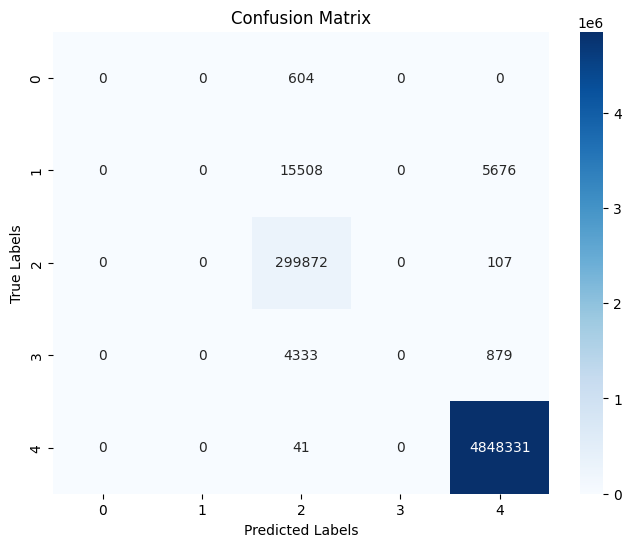

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [10]:
model_type1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_type_glob_model.h5')
model_type1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_type_3rd_round_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
model_type1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])
y1_pred = model_type1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

# Print the results
                                                                                             

In [11]:
print(f"Accuracy for 5 class classification 3rd_round fl: {accuracy:.4f}")
print(f"Precision for 5 class classification 3rd_round fl: {precision:.4f}")
print(f"Recall for 5 class classification 3rd_round fl: {recall:.4f}")
print(f"F1 Score for 5 class classification 3rd_round fl: {f1:.4f}")
print(f"MCC for 5 class classification 3rd_round fl: {mcc:.4f}")

Accuracy for 5 class classification 3rd_round fl: 0.9948
Precision for 5 class classification 3rd_round fl: 0.3869
Recall for 5 class classification 3rd_round fl: 0.3999
F1 Score for 5 class classification 3rd_round fl: 0.3932
MCC for 5 class classification 3rd_round fl: 0.9556


CNN_GRU MDPI before FL

In [7]:
cnn_gru_mdpi = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/firstinitialized/CNN_GRU_MDPI_Type_glob_model.h5')
cnn_gru_mdpi.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])

In [ ]:
#cnn_gru_mdpi.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2)
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_cnn_gru_mdpi_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)




cnn_gru_mdpi.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


Epoch 1/5
301882/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9995 - loss: 0.0024
Epoch 1: val_loss improved from inf to 0.00027, saving model to D:/linthoi/FL_models/new/client2/type/client2_cnn_gru_mdpi_type_bfore_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 1083s 4ms/step - accuracy: 0.9995 - loss: 0.0024 - val_accuracy: 0.9999 - val_loss: 2.6904e-04
Epoch 2/5
301889/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9999 - loss: 4.9947e-04
Epoch 2: val_loss improved from 0.00027 to 0.00022, saving model to D:/linthoi/FL_models/new/client2/type/client2_cnn_gru_mdpi_type_bfore_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 907s 3ms/step - accuracy: 0.9999 - loss: 4.9947e-04 - val_accuracy: 1.0000 - val_loss: 2.2357e-04
Epoch 3/5
301879/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9999 - loss: 4.7245e-04

Epoch 1/3
301892/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9999 - loss: 4.8175e-04
Epoch 1: val_loss improved from inf to 0.00041, saving model to D:/linthoi/FL_models/new/client2/type/client2_cnn_gru_mdpi_type_bfore_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 842s 3ms/step - accuracy: 0.9999 - loss: 4.8175e-04 - val_accuracy: 0.9999 - val_loss: 4.1329e-04
Epoch 2/3
301893/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9999 - loss: 4.0805e-04
Epoch 2: val_loss improved from 0.00041 to 0.00028, saving model to D:/linthoi/FL_models/new/client2/type/client2_cnn_gru_mdpi_type_bfore_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 891s 3ms/step - accuracy: 0.9999 - loss: 4.0805e-04 - val_accuracy: 0.9999 - val_loss: 2.7750e-04
Epoch 3/3
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9999 - loss: 4.2021e-04
Epoch 3: val_loss did not improve from 0.00028
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 915s 3ms/step - accuracy: 0.9999 - loss: 4.2021e-04 - val_accur

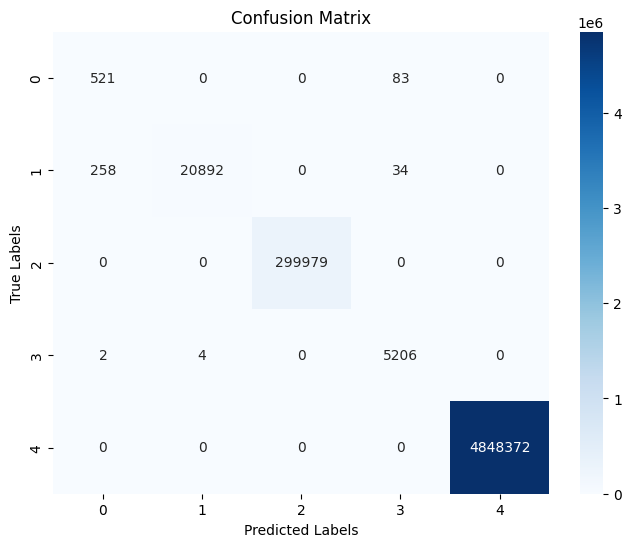

In [6]:
#cnn_gru_mdpi.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2)
from tensorflow.keras.callbacks import ModelCheckpoint
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_cnn_gru_mdpi_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
#Load the saved keras model from the previous epoch
w1= load_model('D:/linthoi/FL_models/new/client2/type/client2_cnn_gru_mdpi_type_bfore_FL_weight.keras')

w1.fit(X1_train_r, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = w1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 5 class classification cnn_gru_mdpi_bfore fl: {accuracy:.4f}")
print(f"Precision for 5 class classification cnn_gru_mdpi_bfore fl: {precision:.4f}")
print(f"Recall for 5 class classification cnn_gru_mdpi_bfore fl: {recall:.4f}")
print(f"F1 Score for 5 class classification cnn_gru_mdpi_bfore fl: {f1:.4f}")
print(f"MCC for 5 class classification cnn_gru_mdpi_bfore fl: {mcc:.4f}")

Accuracy for 5 class classification cnn_gru_mdpi_bfore fl: 0.9999
Precision for 5 class classification cnn_gru_mdpi_bfore fl: 0.9290
Recall for 5 class classification cnn_gru_mdpi_bfore fl: 0.9695
F1 Score for 5 class classification cnn_gru_mdpi_bfore fl: 0.9467
MCC for 5 class classification cnn_gru_mdpi_bfore fl: 0.9994


1st fl round cnn_gru_mdpi type

Epoch 1/5
301892/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9998 - loss: 8.0152e-04
Epoch 1: val_loss improved from inf to 0.00020, saving model to D:/linthoi/FL_models/new/client2/type/client2_cnn_gru_mdpi_type_1stround_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 4470s 15ms/step - accuracy: 0.9998 - loss: 8.0152e-04 - val_accuracy: 0.9999 - val_loss: 2.0049e-04
Epoch 2/5
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9999 - loss: 4.3733e-04
Epoch 2: val_loss did not improve from 0.00020
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 4026s 13ms/step - accuracy: 0.9999 - loss: 4.3733e-04 - val_accuracy: 0.9999 - val_loss: 6.8058e-04
Epoch 3/5
301892/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9999 - loss: 4.5594e-04
Epoch 3: val_loss did not improve from 0.00020
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 3953s 13ms/step - accuracy: 0.9999 - loss: 4.5594e-04 - val_accuracy: 0.9997 - val_loss: 0.0014
Epoch 4/5
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accu

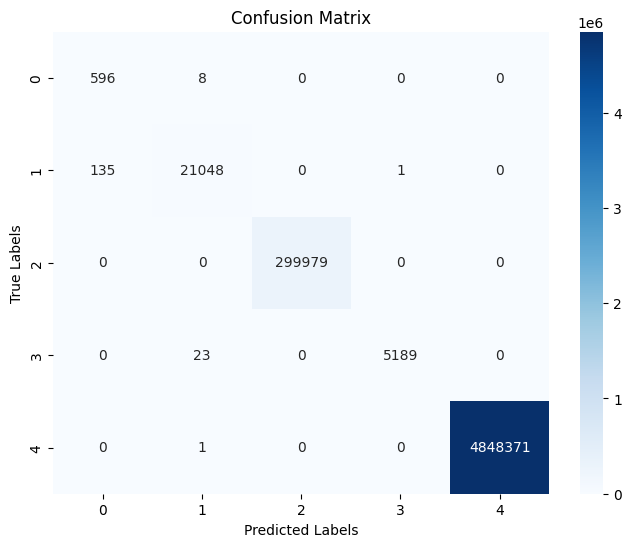

In [8]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_CNN_GRU_MDPI_Type_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_cnn_gru_mdpi_type_1stround_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 5 class classification cnn_gru_mdpi_1stround fl: {accuracy:.4f}")
print(f"Precision for 5 class classification cnn_gru_mdpi_1stround fl: {precision:.4f}")
print(f"Recall for 5 class classification cnn_gru_mdpi_1stround fl: {recall:.4f}")
print(f"F1 Score for 5 class classification cnn_gru_mdpi_1stround fl: {f1:.4f}")
print(f"MCC for 5 class classification cnn_gru_mdpi_1stround fl: {mcc:.4f}")

Accuracy for 5 class classification cnn_gru_mdpi_1stround fl: 1.0000
Precision for 5 class classification cnn_gru_mdpi_1stround fl: 0.9627
Recall for 5 class classification cnn_gru_mdpi_1stround fl: 0.9952
F1 Score for 5 class classification cnn_gru_mdpi_1stround fl: 0.9773
MCC for 5 class classification cnn_gru_mdpi_1stround fl: 0.9997


2nd fl round cnn_gru_model (type)

Epoch 1/5
301881/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9999 - loss: 4.2151e-04
Epoch 1: val_loss improved from inf to 0.00031, saving model to D:/linthoi/FL_models/new/client2/type/client2_cnn_gru_mdpi_type_2ndround_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 928s 3ms/step - accuracy: 0.9999 - loss: 4.2151e-04 - val_accuracy: 0.9999 - val_loss: 3.1419e-04
Epoch 2/5
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9999 - loss: 3.7555e-04
Epoch 2: val_loss improved from 0.00031 to 0.00027, saving model to D:/linthoi/FL_models/new/client2/type/client2_cnn_gru_mdpi_type_2ndround_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 894s 3ms/step - accuracy: 0.9999 - loss: 3.7555e-04 - val_accuracy: 0.9999 - val_loss: 2.6967e-04
Epoch 3/5
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9999 - loss: 4.0556e-04
Epoch 3: val_loss did not improve from 0.00027
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 909s 3ms/step - accuracy: 0.9999 - loss: 4.0556e-04 - val

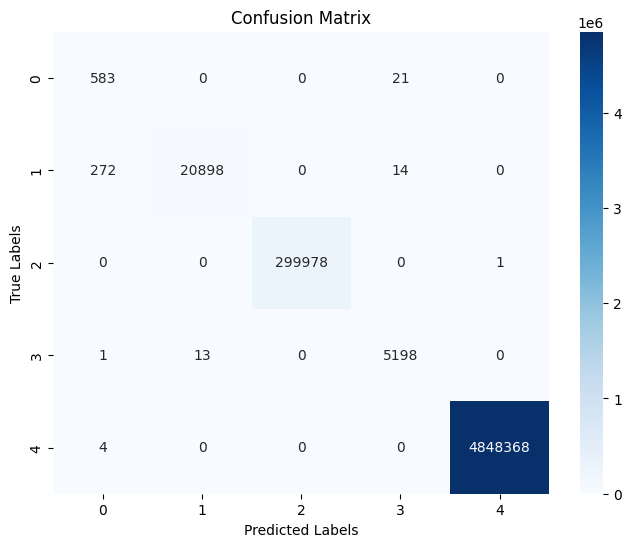

In [6]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_CNN_GRU_MDPI_Type_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_cnn_gru_mdpi_type_2ndround_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 5 class classification cnn_gru_mdpi_2ndround fl: {accuracy:.4f}")
print(f"Precision for 5 class classification cnn_gru_mdpi_2ndround fl: {precision:.4f}")
print(f"Recall for 5 class classification cnn_gru_mdpi_2ndround fl: {recall:.4f}")
print(f"F1 Score for 5 class classification cnn_gru_mdpi_2ndround fl: {f1:.4f}")
print(f"MCC for 5 class classification cnn_gru_mdpi_2ndround fl: {mcc:.4f}")

Accuracy for 5 class classification cnn_gru_mdpi_2ndround fl: 0.9999
Precision for 5 class classification cnn_gru_mdpi_2ndround fl: 0.9341
Recall for 5 class classification cnn_gru_mdpi_2ndround fl: 0.9898
F1 Score for 5 class classification cnn_gru_mdpi_2ndround fl: 0.9569
MCC for 5 class classification cnn_gru_mdpi_2ndround fl: 0.9995


3rd fl round cnn_gru_mdpi (type)

Epoch 1/5
301893/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 0.9999 - loss: 4.1996e-04
Epoch 1: val_loss improved from inf to 0.00019, saving model to D:/linthoi/FL_models/new/client2/type/client2_cnn_gru_mdpi_type_3rdround_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 3939s 13ms/step - accuracy: 0.9999 - loss: 4.1996e-04 - val_accuracy: 1.0000 - val_loss: 1.8749e-04
Epoch 2/5
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9999 - loss: 3.7905e-04
Epoch 2: val_loss did not improve from 0.00019
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 3581s 12ms/step - accuracy: 0.9999 - loss: 3.7905e-04 - val_accuracy: 0.9999 - val_loss: 6.9136e-04
Epoch 3/5
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.9999 - loss: 3.8921e-04
Epoch 3: val_loss did not improve from 0.00019
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 3617s 12ms/step - accuracy: 0.9999 - loss: 3.8921e-04 - val_accuracy: 0.9999 - val_loss: 6.9106e-04
Epoch 4/5
301894/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - 

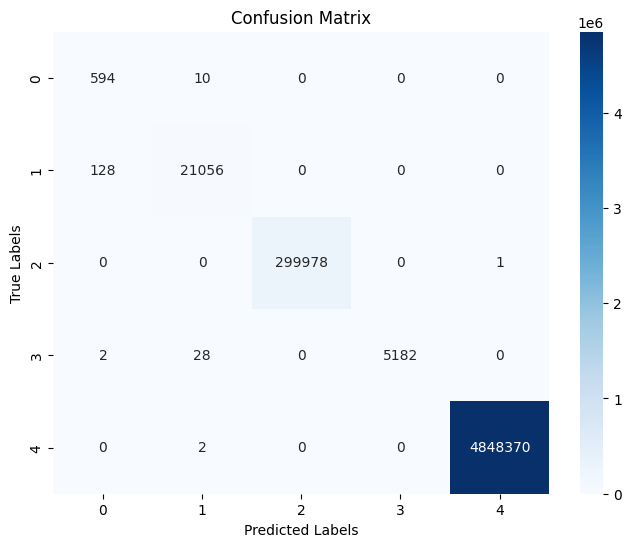

In [8]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_CNN_GRU_MDPI_Type_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_cnn_gru_mdpi_type_3rdround_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 5 class classification cnn_gru_mdpi_3rdround fl: {accuracy:.4f}")
print(f"Precision for 5 class classification cnn_gru_mdpi_3rdround fl: {precision:.4f}")
print(f"Recall for 5 class classification cnn_gru_mdpi_3rdround fl: {recall:.4f}")
print(f"F1 Score for 5 class classification cnn_gru_mdpi_3rdround fl: {f1:.4f}")
print(f"MCC for 5 class classification cnn_gru_mdpi_3rdround fl: {mcc:.4f}")

Accuracy for 5 class classification cnn_gru_mdpi_3rdround fl: 1.0000
Precision for 5 class classification cnn_gru_mdpi_3rdround fl: 0.9637
Recall for 5 class classification cnn_gru_mdpi_3rdround fl: 0.9943
F1 Score for 5 class classification cnn_gru_mdpi_3rdround fl: 0.9775
MCC for 5 class classification cnn_gru_mdpi_3rdround fl: 0.9997


before fl cnn_gru_mdpi (binary)

In [10]:
X1=c1.iloc[:, :-3]
y1 = c1.iloc[:, -3]
X1 = scaler.fit_transform(X1)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, random_state=42)
X1_train_r = X1_train.reshape((X1_train.shape[0], 1 , X1_train.shape[1]))
X1_test_r = X1_test.reshape((X1_test.shape[0], 1 ,X1_test.shape[1]))

In [11]:
y1

0          1
1          1
2          1
3          1
4          1
          ..
6264105    1
6264106    1
6264107    1
6264108    1
6264109    1
Name: label, Length: 6264110, dtype: int64

Epoch 1/5
109615/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9996 - loss: 0.0011
Epoch 1: val_loss improved from inf to 0.00000, saving model to D:/linthoi/FL_models/new/client2/binary/client2_cnn_gru_mdpi_binary_bfore_FL_weight_iid.keras
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 527s 5ms/step - accuracy: 0.9996 - loss: 0.0011 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/5
109616/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 1.0000 - loss: 4.0532e-13
Epoch 2: val_loss did not improve from 0.00000
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 549s 5ms/step - accuracy: 1.0000 - loss: 4.0532e-13 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/5
109618/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 2.4355e-13
Epoch 3: val_loss did not improve from 0.00000
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 473s 4ms/step - accuracy: 1.0000 - loss: 2.4355e-13 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 4/5
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0

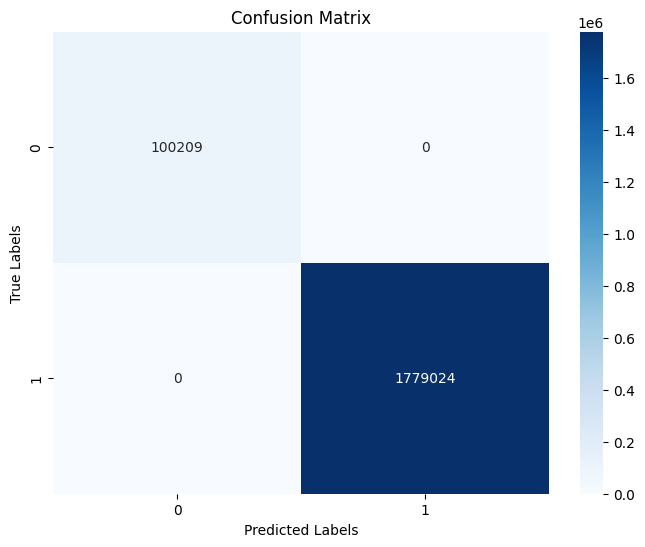

In [12]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Binary_glob_model/firstinitialized/CNN_GRU_MDPI_binary_glob_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/binary/client2_cnn_gru_mdpi_binary_bfore_FL_weight_iid.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [13]:
print(f"Accuracy for 2 class classification cnn_gru_mdpi_bforefl: {accuracy:.4f}")
print(f"Precision for 2 class classification cnn_gru_mdpi_bforefl fl: {precision:.4f}")
print(f"Recall for 2 class classification cnn_gru_mdpi_bforefl fl: {recall:.4f}")
print(f"F1 Score for 2 class classification cnn_gru_mdpi_bforefl fl: {f1:.4f}")
print(f"MCC for 2 class classification cnn_gru_mdpi_bforefl fl: {mcc:.4f}")

Accuracy for 2 class classification cnn_gru_mdpi_bforefl: 1.0000
Precision for 2 class classification cnn_gru_mdpi_bforefl fl: 1.0000
Recall for 2 class classification cnn_gru_mdpi_bforefl fl: 1.0000
F1 Score for 2 class classification cnn_gru_mdpi_bforefl fl: 1.0000
MCC for 2 class classification cnn_gru_mdpi_bforefl fl: 1.0000


before fl round categorical classification cnn_gru_mdpi

In [4]:
X1=c1.iloc[:, :-3]
y1 = c1.iloc[:, -2]
X1 = scaler.fit_transform(X1)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, random_state=42)
X1_train_r = X1_train.reshape((X1_train.shape[0], 1 , X1_train.shape[1]))
X1_test_r = X1_test.reshape((X1_test.shape[0], 1 ,X1_test.shape[1]))

In [18]:
y1.value_counts()

category
1    5385025
3     334638
2     165243
6     147954
0     122999
5     102654
4       5597
Name: count, dtype: int64

Epoch 1/5
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9979 - loss: 0.0104
Epoch 1: val_loss improved from inf to 0.00224, saving model to D:/linthoi/FL_models/new/client2/category/client2_cnn_gru_mdpi_cate_1st_FL_weight_iid.keras
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 404s 4ms/step - accuracy: 0.9979 - loss: 0.0104 - val_accuracy: 0.9992 - val_loss: 0.0022
Epoch 2/5
109612/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9991 - loss: 0.0027
Epoch 2: val_loss improved from 0.00224 to 0.00198, saving model to D:/linthoi/FL_models/new/client2/category/client2_cnn_gru_mdpi_cate_1st_FL_weight_iid.keras
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 346s 3ms/step - accuracy: 0.9991 - loss: 0.0027 - val_accuracy: 0.9993 - val_loss: 0.0020
Epoch 3/5
109617/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.9992 - loss: 0.0026
Epoch 3: val_loss did not improve from 0.00198
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 312s 3ms/step - accuracy: 0.9992 - loss: 0.0026 - val_accuracy: 0.9992 - val_lo

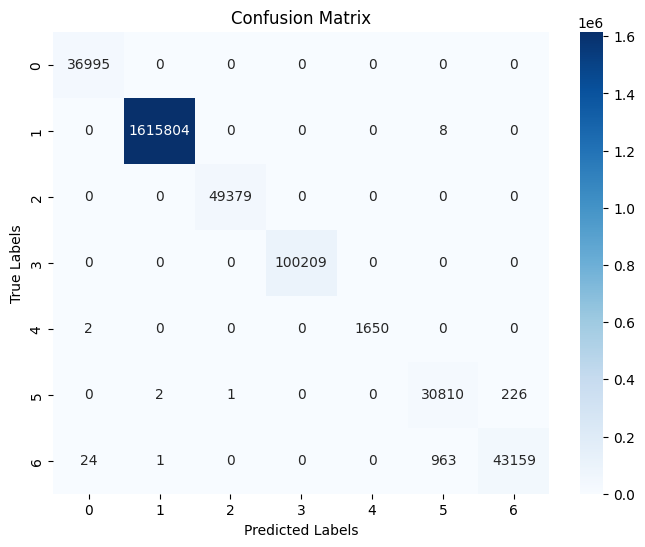

In [5]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/1stround_CNN_GRU_MDPI_cate_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/category/client2_cnn_gru_mdpi_cate_1st_FL_weight_iid.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [ ]:
print(f"Accuracy for 4 class classification cnn_gru_mdpi_1stfl: {accuracy:.4f}")
print(f"Precision for 4 class classification cnn_gru_mdpi_1stfl fl: {precision:.4f}")
print(f"Recall for 4 class classification cnn_gru_mdpi_1stfl fl: {recall:.4f}")
print(f"F1 Score for 4 class classification cnn_gru_mdpi_1stfl fl: {f1:.4f}")
print(f"MCC for 4 class classification cnn_gru_mdpi_1stfl fl: {mcc:.4f}")

Accuracy for 4 class classification cnn_gru_mdpi_bforefl: 1.0000
Precision for 4 class classification cnn_gru_mdpi_bforefl fl: 0.9996
Recall for 4 class classification cnn_gru_mdpi_bforefl fl: 0.9988
F1 Score for 4 class classification cnn_gru_mdpi_bforefl fl: 0.9992
MCC for 4 class classification cnn_gru_mdpi_bforefl fl: 1.0000


1st fl round

Epoch 1/5
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9999 - loss: 7.3553e-04
Epoch 1: val_loss improved from inf to 0.00008, saving model to D:/linthoi/FL_models/new/client2/category/client2_cnn_gru_mdpi_cate_1st_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 4826s 16ms/step - accuracy: 0.9999 - loss: 7.3553e-04 - val_accuracy: 1.0000 - val_loss: 7.7775e-05
Epoch 2/5
301894/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 2.3953e-04
Epoch 2: val_loss did not improve from 0.00008
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 4234s 14ms/step - accuracy: 1.0000 - loss: 2.3953e-04 - val_accuracy: 0.9997 - val_loss: 0.0016
Epoch 3/5
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 3.0238e-04
Epoch 3: val_loss improved from 0.00008 to 0.00008, saving model to D:/linthoi/FL_models/new/client2/category/client2_cnn_gru_mdpi_cate_1st_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 3747s 12ms/step - accuracy: 1.0000 - loss: 3.0238e-04 - 

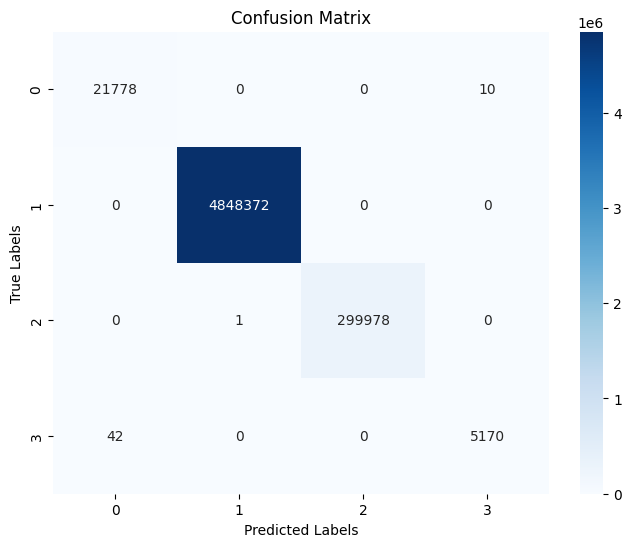

In [13]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/1st_round_CNN_GRU_MDPI_cate_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/category/client2_cnn_gru_mdpi_cate_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [14]:
print(f"Accuracy for 4 class classification cnn_gru_mdpi_1stfl: {accuracy:.4f}")
print(f"Precision for 4 class classification cnn_gru_mdpi_1stfl fl: {precision:.4f}")
print(f"Recall for 4 class classification cnn_gru_mdpi_1stfl fl: {recall:.4f}")
print(f"F1 Score for 4 class classification cnn_gru_mdpi_1stfl fl: {f1:.4f}")
print(f"MCC for 4 class classification cnn_gru_mdpi_1stfl fl: {mcc:.4f}")

Accuracy for 4 class classification cnn_gru_mdpi_1stfl: 1.0000
Precision for 4 class classification cnn_gru_mdpi_1stfl fl: 0.9990
Recall for 4 class classification cnn_gru_mdpi_1stfl fl: 0.9979
F1 Score for 4 class classification cnn_gru_mdpi_1stfl fl: 0.9985
MCC for 4 class classification cnn_gru_mdpi_1stfl fl: 0.9999


2nd round

Epoch 1/3
301893/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9999 - loss: 3.6939e-04
Epoch 1: val_loss improved from inf to 0.00025, saving model to D:/linthoi/FL_models/new/client2/category/client2_cnn_gru_mdpi_cate_2nd_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 4712s 16ms/step - accuracy: 0.9999 - loss: 3.6938e-04 - val_accuracy: 1.0000 - val_loss: 2.5030e-04
Epoch 2/3
301894/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 1.0000 - loss: 2.4509e-04
Epoch 2: val_loss improved from 0.00025 to 0.00007, saving model to D:/linthoi/FL_models/new/client2/category/client2_cnn_gru_mdpi_cate_2nd_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 4031s 13ms/step - accuracy: 1.0000 - loss: 2.4509e-04 - val_accuracy: 1.0000 - val_loss: 7.3464e-05
Epoch 3/3
301894/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - accuracy: 1.0000 - loss: 2.2348e-04
Epoch 3: val_loss did not improve from 0.00007
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 3794s 13ms/step - accuracy: 1.0000 - loss: 2.2348e-0

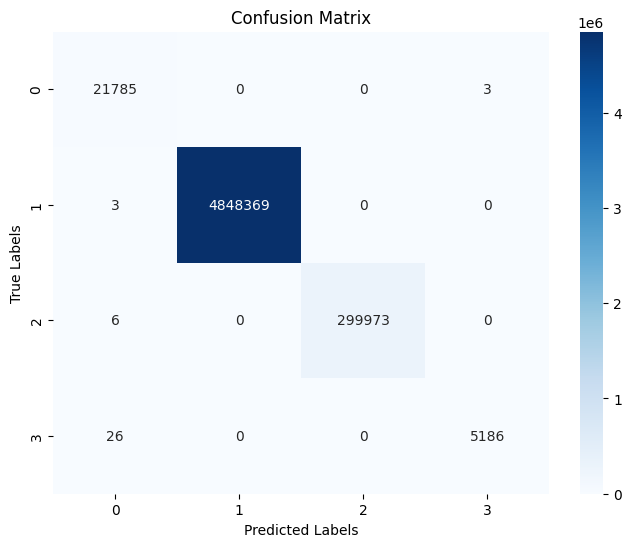

In [15]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
cnn_gru_mdpi1 = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/2nd_round_CNN_GRU_MDPI_cate_model.h5')
cnn_gru_mdpi1.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/category/client2_cnn_gru_mdpi_cate_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
cnn_gru_mdpi1.fit(X1_train_r, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])
y1_pred = cnn_gru_mdpi1.predict(X1_test_r) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [16]:
print(f"Accuracy for 4 class classification cnn_gru_mdpi_2ndfl: {accuracy:.4f}")
print(f"Precision for 4 class classification cnn_gru_mdpi_2ndfl fl: {precision:.4f}")
print(f"Recall for 4 class classification cnn_gru_mdpi_2ndfl fl: {recall:.4f}")
print(f"F1 Score for 4 class classification cnn_gru_mdpi_2ndfl fl: {f1:.4f}")
print(f"MCC for 4 class classification cnn_gru_mdpi_2ndfl fl: {mcc:.4f}")

Accuracy for 4 class classification cnn_gru_mdpi_2ndfl: 1.0000
Precision for 4 class classification cnn_gru_mdpi_2ndfl fl: 0.9995
Recall for 4 class classification cnn_gru_mdpi_2ndfl fl: 0.9987
F1 Score for 4 class classification cnn_gru_mdpi_2ndfl fl: 0.9991
MCC for 4 class classification cnn_gru_mdpi_2ndfl fl: 0.9999


PCC_CNN binary before fl

In [14]:
X1=c1.iloc[:, :-3]
y1 = c1.iloc[:, -3]
X1 = scaler.fit_transform(X1)
X1_train, X1_test, y1_train, y1_test = train_test_split(X1, y1, test_size=0.3, random_state=42)

In [15]:
y1.value_counts()

label
1    5929472
0     334638
Name: count, dtype: int64

Epoch 1/3
109617/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.9995 - loss: 0.0016
Epoch 1: val_loss improved from inf to 0.00000, saving model to D:/linthoi/FL_models/new/client2/binary/client1_pcc_cnn_ieee_binary_bfore_FL_weight_iid.keras
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 836s 8ms/step - accuracy: 0.9995 - loss: 0.0016 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 2/3
109615/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 1.0000 - loss: 1.7478e-12
Epoch 2: val_loss did not improve from 0.00000
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 738s 7ms/step - accuracy: 1.0000 - loss: 1.7478e-12 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Epoch 3/3
109617/109622 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 1.0000 - loss: 2.8286e-12
Epoch 3: val_loss did not improve from 0.00000
109622/109622 ━━━━━━━━━━━━━━━━━━━━ 874s 8ms/step - accuracy: 1.0000 - loss: 2.8287e-12 - val_accuracy: 1.0000 - val_loss: 0.0000e+00
Restoring model weights from the end of the best epoch: 1.
58727/58727 ━

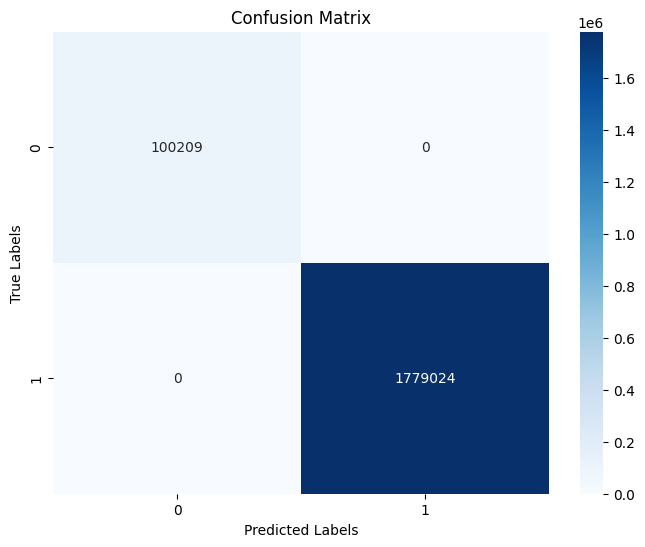

In [16]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn = load_model(r'D:\linthoi\FL_models\new\glob_models\Binary_glob_model\firstinitialized\pcc_cnn_bin_glob_model.h5')
pcc_cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/binary/client1_pcc_cnn_ieee_binary_bfore_FL_weight_iid.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn.fit(X1_train, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])
y1_pred = pcc_cnn.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [ ]:
print(f"Accuracy for 2 class classification pcc_cnn_bin_bforeFL: {accuracy:.4f}")
print(f"Precision for 2 class classification pcc_cnn_bin_bforeFL fl: {precision:.4f}")
print(f"Recall for 2 class classification pcc_cnn_bin_bforeFL fl: {recall:.4f}")
print(f"F1 Score for 2 class classification pcc_cnn_bin_bforeFL fl: {f1:.4f}")
print(f"MCC for 2 class classification pcc_cnn_bin_bforeFL fl: {mcc:.4f}")

Accuracy for 2 class classification pcc_cnn_bin_bforeFL: 1.0000
Precision for 2 class classification pcc_cnn_bin_bforeFL fl: 1.0000
Recall for 2 class classification pcc_cnn_bin_bforeFL fl: 1.0000
F1 Score for 2 class classification pcc_cnn_bin_bforeFL fl: 1.0000
MCC for 2 class classification pcc_cnn_bin_bforeFL fl: 1.0000


pcc cnn 4 class classification before fl

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn = load_model(r'D:\linthoi\FL_models\new\glob_models\Category_glob_model\firstinitialized\pcc_cnn_cate_glob_model.h5')
pcc_cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/category/client2_pcc_cnn_ieee_cate_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn.fit(X1_train, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])
y1_pred = pcc_cnn.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


Epoch 1/3
301893/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9995 - loss: 0.0019
Epoch 1: val_loss improved from inf to 0.00007, saving model to D:/linthoi/FL_models/new/client2/category/client2_pcc_cnn_ieee_cate_bfore_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 5181s 17ms/step - accuracy: 0.9995 - loss: 0.0019 - val_accuracy: 1.0000 - val_loss: 7.3511e-05
Epoch 2/3
301893/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 1.0000 - loss: 4.5079e-05

In [6]:
prev_trained_model = tf.keras.models.load_model("D:/linthoi/FL_models/new/client2/category/client2_pcc_cnn_ieee_cate_bfore_FL_weight.keras")
WC1=prev_trained_model.get_weights()

In [7]:
pcc_cnn = load_model(r'D:\linthoi\FL_models\new\glob_models\Category_glob_model\firstinitialized\pcc_cnn_cate_glob_model.h5')
pcc_cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
pcc_cnn.set_weights(WC1)

301896/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 1.0000 - loss: 5.3823e-05
Epoch 1: val_loss improved from inf to 0.00000, saving model to D:/linthoi/FL_models/new/client2/category/client2_pcc_cnn_ieee_cate_bfore_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 1352s 4ms/step - accuracy: 1.0000 - loss: 5.3823e-05 - val_accuracy: 1.0000 - val_loss: 1.5052e-09
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 364s 2ms/step
Accuracy Score: 1.0


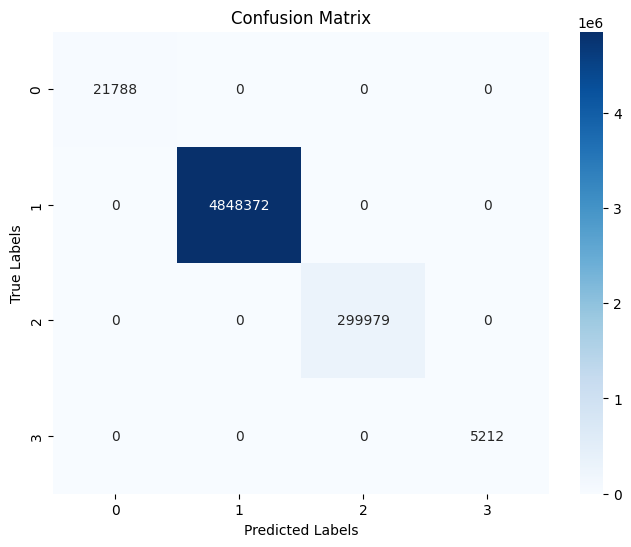

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)

#pcc_cnn.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/category/client2_pcc_cnn_ieee_cate_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[early_stopping, checkpoint_callback])
y1_pred = pcc_cnn.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 4 class classification pcc_cnn_cate_bforeFL: {accuracy:.4f}")
print(f"Precision for 4 class classification pcc_cnn_cate_bforeFL fl: {precision:.4f}")
print(f"Recall for 4 class classification pcc_cnn_cate_bforeFL fl: {recall:.4f}")
print(f"F1 Score for 4 class classification pcc_cnn_cate_bforeFL fl: {f1:.4f}")
print(f"MCC for 4 class classification pcc_cnn_cate_bforeFL fl: {mcc:.4f}")

Accuracy for 4 class classification pcc_cnn_cate_bforeFL: 1.0000
Precision for 4 class classification pcc_cnn_cate_bforeFL fl: 1.0000
Recall for 4 class classification pcc_cnn_cate_bforeFL fl: 1.0000
F1 Score for 4 class classification pcc_cnn_cate_bforeFL fl: 1.0000
MCC for 4 class classification pcc_cnn_cate_bforeFL fl: 1.0000


PCC_CNN type classification before FL

Epoch 1/3
301893/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9995 - loss: 0.0022
Epoch 1: val_loss improved from inf to 0.00023, saving model to D:/linthoi/FL_models/new/client2/type/client2_pcc_cnn_ieee_type_bfore_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 4671s 15ms/step - accuracy: 0.9995 - loss: 0.0022 - val_accuracy: 0.9999 - val_loss: 2.3090e-04
Epoch 2/3
301892/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - accuracy: 0.9999 - loss: 2.4338e-04
Epoch 2: val_loss improved from 0.00023 to 0.00013, saving model to D:/linthoi/FL_models/new/client2/type/client2_pcc_cnn_ieee_type_bfore_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 4506s 15ms/step - accuracy: 0.9999 - loss: 2.4338e-04 - val_accuracy: 1.0000 - val_loss: 1.3408e-04
Epoch 3/3
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - accuracy: 0.9999 - loss: 2.3888e-04
Epoch 3: val_loss improved from 0.00013 to 0.00013, saving model to D:/linthoi/FL_models/new/client2/type/client2_pcc_cnn_ieee_type_bfore_FL_weigh

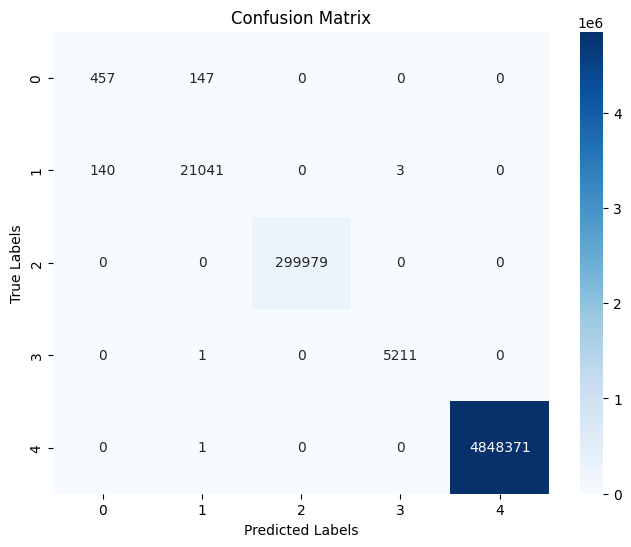

In [9]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn_type = load_model(r'D:\linthoi\FL_models\new\glob_models\Type_glob_model\firstinitialized\pcc_cnn_type_glob_model.h5')
pcc_cnn_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_pcc_cnn_ieee_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn_type.fit(X1_train, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn_type.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [10]:
print(f"Accuracy for 4 class classification pcc_cnn_type_bforeFL: {accuracy:.4f}")
print(f"Precision for 4 class classification pcc_cnn_type_bforeFL fl: {precision:.4f}")
print(f"Recall for 4 class classification pcc_cnn_type_bforeFL fl: {recall:.4f}")
print(f"F1 Score for 4 class classification pcc_cnn_type_bforeFL fl: {f1:.4f}")
print(f"MCC for 4 class classification pcc_cnn_type_bforeFL fl: {mcc:.4f}")

Accuracy for 4 class classification pcc_cnn_type_bforeFL: 0.9999
Precision for 4 class classification pcc_cnn_type_bforeFL fl: 0.9516
Recall for 4 class classification pcc_cnn_type_bforeFL fl: 0.9499
F1 Score for 4 class classification pcc_cnn_type_bforeFL fl: 0.9508
MCC for 4 class classification pcc_cnn_type_bforeFL fl: 0.9995


1st fl round pcc_cnn type classification

Epoch 1/3
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9994 - loss: 0.0026
Epoch 1: val_loss improved from inf to 0.00015, saving model to D:/linthoi/FL_models/new/client2/type/client2_pcc_cnn_ieee_type_1st_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 5081s 17ms/step - accuracy: 0.9994 - loss: 0.0026 - val_accuracy: 0.9999 - val_loss: 1.5042e-04
Epoch 2/3
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9999 - loss: 2.7091e-04
Epoch 2: val_loss improved from 0.00015 to 0.00013, saving model to D:/linthoi/FL_models/new/client2/type/client2_pcc_cnn_ieee_type_1st_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 4965s 16ms/step - accuracy: 0.9999 - loss: 2.7091e-04 - val_accuracy: 0.9999 - val_loss: 1.3494e-04
Epoch 3/3
301893/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9999 - loss: 2.1976e-04
Epoch 3: val_loss did not improve from 0.00013
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 5038s 17ms/step - accuracy: 0.9999 - loss: 2.1976e-04 - val_accuracy

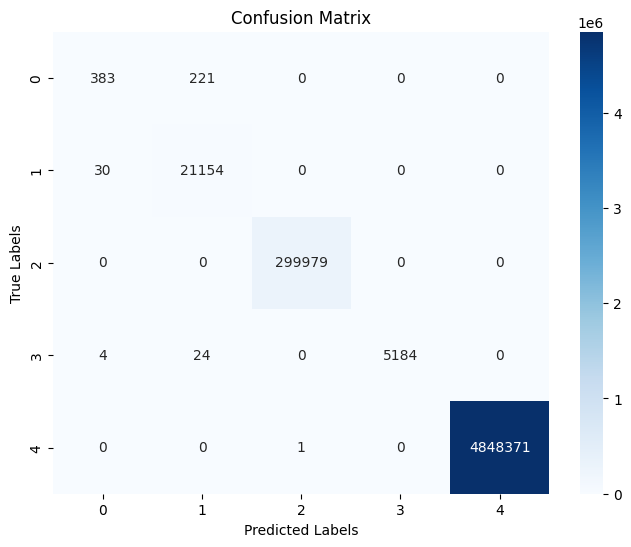

In [11]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn_type = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_pcc_cnn_type_glob_model.h5')
pcc_cnn_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_pcc_cnn_ieee_type_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn_type.fit(X1_train, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn_type.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [12]:
print(f"Accuracy for 5 class classification pcc_cnn_type_bforeFL: {accuracy:.4f}")
print(f"Precision for 5 class classification pcc_cnn_type_bforeFL fl: {precision:.4f}")
print(f"Recall for 5 class classification pcc_cnn_type_bforeFL fl: {recall:.4f}")
print(f"F1 Score for 5 class classification pcc_cnn_type_bforeFL fl: {f1:.4f}")
print(f"MCC for 5 class classification pcc_cnn_type_bforeFL fl: {mcc:.4f}")

Accuracy for 5 class classification pcc_cnn_type_bforeFL: 0.9999
Precision for 5 class classification pcc_cnn_type_bforeFL fl: 0.9814
Recall for 5 class classification pcc_cnn_type_bforeFL fl: 0.9255
F1 Score for 5 class classification pcc_cnn_type_bforeFL fl: 0.9482
MCC for 5 class classification pcc_cnn_type_bforeFL fl: 0.9995


2nd fl round pcc_cnn type classification

Epoch 1/3
301888/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.9999 - loss: 2.8855e-04
Epoch 1: val_loss improved from inf to 0.00027, saving model to D:/linthoi/FL_models/new/client2/type/client2_pcc_cnn_ieee_type_2nd_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 1827s 6ms/step - accuracy: 0.9999 - loss: 2.8855e-04 - val_accuracy: 0.9999 - val_loss: 2.6513e-04
Epoch 2/3
301890/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9999 - loss: 2.5539e-04
Epoch 2: val_loss did not improve from 0.00027
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 1513s 5ms/step - accuracy: 0.9999 - loss: 2.5539e-04 - val_accuracy: 0.9999 - val_loss: 2.9635e-04
Epoch 3/3
301892/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9999 - loss: 2.4777e-04
Epoch 3: val_loss did not improve from 0.00027
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 1742s 6ms/step - accuracy: 0.9999 - loss: 2.4777e-04 - val_accuracy: 0.9999 - val_loss: 2.7609e-04
Restoring model weights from the end of the best epoch: 1.
161730/16173

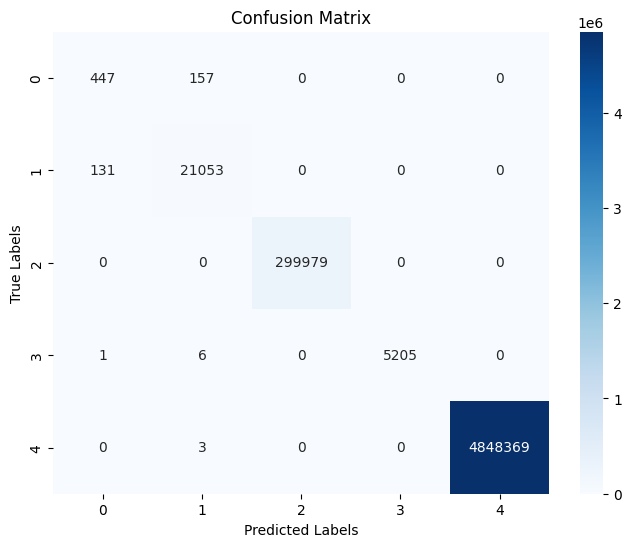

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn_type = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_pcc_cnn_type_glob_model.h5')
pcc_cnn_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_pcc_cnn_ieee_type_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn_type.fit(X1_train, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn_type.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 5 class classification pcc_cnn_type_2nd FL: {accuracy:.4f}")
print(f"Precision for 5 class classification pcc_cnn_type_2nd fl: {precision:.4f}")
print(f"Recall for 5 class classification pcc_cnn_type_2nd fl: {recall:.4f}")
print(f"F1 Score for 5 class classification pcc_cnn_type_2nd fl: {f1:.4f}")
print(f"MCC for 5 class classification pcc_cnn_type_2nd fl: {mcc:.4f}")

Accuracy for 5 class classification pcc_cnn_type_2nd FL: 0.9999
Precision for 5 class classification pcc_cnn_type_2nd fl: 0.9528
Recall for 5 class classification pcc_cnn_type_2nd fl: 0.9465
F1 Score for 5 class classification pcc_cnn_type_2nd fl: 0.9496
MCC for 5 class classification pcc_cnn_type_2nd fl: 0.9995


3rd fl round pcc_cnn type classification

Epoch 1/3
301894/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.9999 - loss: 3.1087e-04
Epoch 1: val_loss improved from inf to 0.00021, saving model to D:/linthoi/FL_models/new/client2/type/client2_pcc_cnn_ieee_type_3rd_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 6147s 20ms/step - accuracy: 0.9999 - loss: 3.1087e-04 - val_accuracy: 0.9999 - val_loss: 2.1386e-04
Epoch 2/3
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.9999 - loss: 2.7197e-04
Epoch 2: val_loss improved from 0.00021 to 0.00012, saving model to D:/linthoi/FL_models/new/client2/type/client2_pcc_cnn_ieee_type_3rd_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 5003s 17ms/step - accuracy: 0.9999 - loss: 2.7197e-04 - val_accuracy: 0.9999 - val_loss: 1.1909e-04
Epoch 3/3
301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.9999 - loss: 2.3664e-04
Epoch 3: val_loss did not improve from 0.00012
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 5632s 19ms/step - accuracy: 0.9999 - loss: 2.3664e-04 - val_

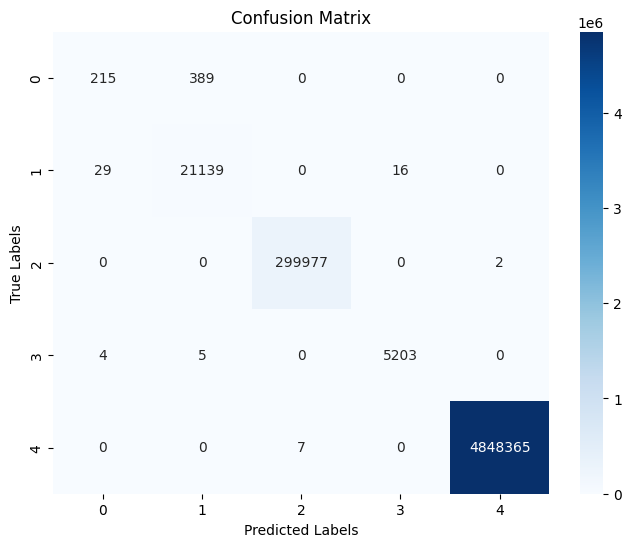

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
pcc_cnn_type = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_pcc_cnn_type_glob_model.h5')
pcc_cnn_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_pcc_cnn_ieee_type_3rd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
pcc_cnn_type.fit(X1_train, y1_train, epochs=3, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = pcc_cnn_type.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 5 class classification pcc_cnn_type_3rd FL: {accuracy:.4f}")
print(f"Precision for 5 class classification pcc_cnn_type_3rd fl: {precision:.4f}")
print(f"Recall for 5 class classification pcc_cnn_type_3rd fl: {recall:.4f}")
print(f"F1 Score for 5 class classification pcc_cnn_type_3rd fl: {f1:.4f}")
print(f"MCC for 5 class classification pcc_cnn_type_3rd fl: {mcc:.4f}")

Accuracy for 5 class classification pcc_cnn_type_3rd FL: 0.9999
Precision for 5 class classification pcc_cnn_type_3rd fl: 0.9691
Recall for 5 class classification pcc_cnn_type_3rd fl: 0.8704
F1 Score for 5 class classification pcc_cnn_type_3rd fl: 0.8984
MCC for 5 class classification pcc_cnn_type_3rd fl: 0.9993


FELIDS binary

In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_bin = load_model(r'D:\linthoi\FL_models\new\glob_models\Binary_glob_model\firstinitialized\felids_cnn_bin.h5')
felids_cnn_bin.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client1/binary/client2_pcc_cnn_ieee_binary_bfore_FL_weight_iid.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_bin.fit(X1_train, y1_train, epochs=5, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_bin.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


FELIDS DNN 4 class classification (category)

301892/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9994 - loss: 0.0025
Epoch 1: val_loss improved from inf to 0.00000, saving model to D:/linthoi/FL_models/new/client2/category/client2_FELIDS_dnn_bfore_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 1346s 4ms/step - accuracy: 0.9994 - loss: 0.0025 - val_accuracy: 1.0000 - val_loss: 2.5439e-06
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 297s 2ms/step
Accuracy Score: 0.9999982609875157


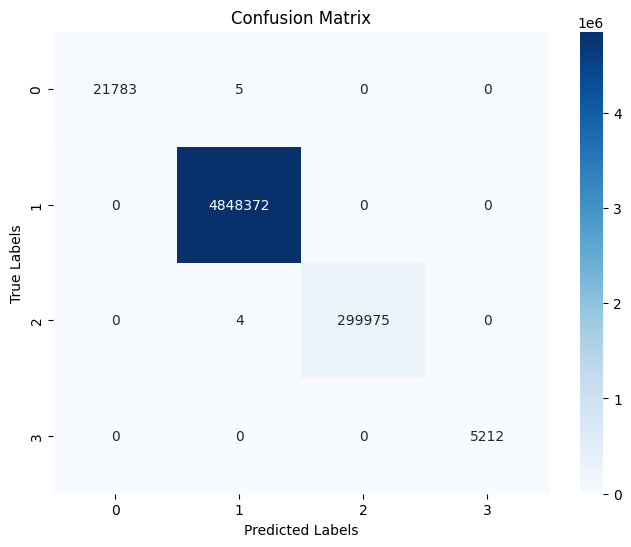

In [9]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model(r'D:\linthoi\FL_models\new\glob_models\Category_glob_model\firstinitialized\felids_dnn_cate.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/category/client2_FELIDS_dnn_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [10]:
print(f"Accuracy for 4 class classification felids_dnn_cate before fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_dnn_cate before fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_dnn_cate before fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_dnn_cate before fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_dnn_cate before fl: {mcc:.4f}")

Accuracy for 4 class classification felids_dnn_cate before fl: 1.0000
Precision for 4 class classification felids_dnn_cate before fl: 1.0000
Recall for 4 class classification felids_dnn_cate before fl: 0.9999
F1 Score for 4 class classification felids_dnn_cate before fl: 1.0000
MCC for 4 class classification felids_dnn_cate before fl: 1.0000


1st fl round

301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.9999 - loss: 3.4959e-04
Epoch 1: val_loss improved from inf to 0.00001, saving model to D:/linthoi/FL_models/new/client2/category/client2_FELIDS_dnn_1st_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 10582s 35ms/step - accuracy: 0.9999 - loss: 3.4959e-04 - val_accuracy: 1.0000 - val_loss: 1.4361e-05
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 1112s 7ms/step
Accuracy Score: 0.9999998067763907


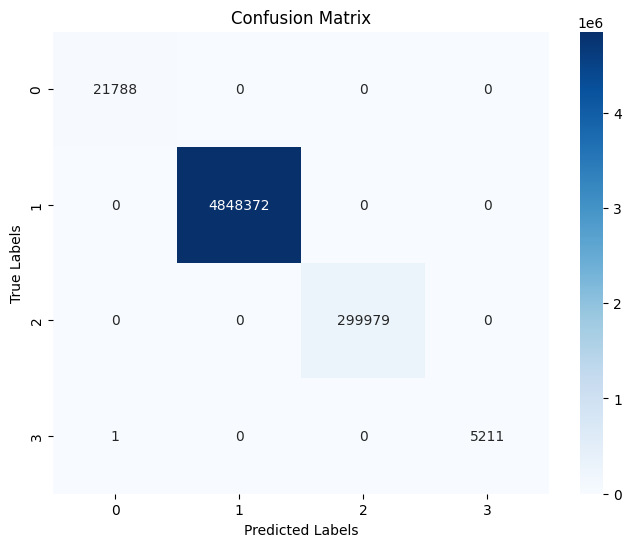

In [11]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/1st_round_felids_dnn_cate_glob_model.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/category/client2_FELIDS_dnn_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [12]:
print(f"Accuracy for 4 class classification felids_dnn_cate 1st fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_dnn_cate 1st fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_dnn_cate 1st fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_dnn_cate 1st fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_dnn_cate 1st fl: {mcc:.4f}")

Accuracy for 4 class classification felids_dnn_cate 1st fl: 1.0000
Precision for 4 class classification felids_dnn_cate 1st fl: 1.0000
Recall for 4 class classification felids_dnn_cate 1st fl: 1.0000
F1 Score for 4 class classification felids_dnn_cate 1st fl: 1.0000
MCC for 4 class classification felids_dnn_cate 1st fl: 1.0000


felids dnn type classification before FL

301875/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.9990 - loss: 0.0043
Epoch 1: val_loss improved from inf to 0.00020, saving model to D:/linthoi/FL_models/new/client2/type/client2_felids_dnn_type_bfore_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 720s 2ms/step - accuracy: 0.9990 - loss: 0.0043 - val_accuracy: 0.9999 - val_loss: 2.0064e-04
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 225s 1ms/step
Accuracy Score: 0.9999211647673752


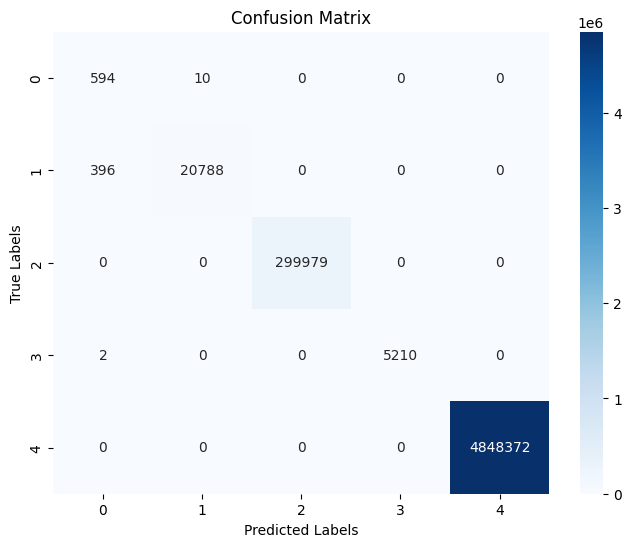

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_type = load_model(r'D:\linthoi\FL_models\new\glob_models\Type_glob_model\firstinitialized\felids_dnn_type.h5')
felids_dnn_type.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_felids_dnn_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_type.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_type.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)

In [7]:
print(f"Accuracy for 5 class classification felids_dnn_type before fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_dnn_type before fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_dnn_type before fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_dnn_type before fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_dnn_type before fl: {mcc:.4f}")

Accuracy for 5 class classification felids_dnn_type before fl: 0.9999
Precision for 5 class classification felids_dnn_type before fl: 0.9197
Recall for 5 class classification felids_dnn_type before fl: 0.9929
F1 Score for 5 class classification felids_dnn_type before fl: 0.9469
MCC for 5 class classification felids_dnn_type before fl: 0.9993


1st round felids dnn type classification

301894/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.9998 - loss: 0.0011
Epoch 1: val_loss improved from inf to 0.00027, saving model to D:/linthoi/FL_models/new/client2/type/client2_felids_dnn_type_1st_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 6765s 22ms/step - accuracy: 0.9998 - loss: 0.0011 - val_accuracy: 0.9999 - val_loss: 2.7245e-04
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 741s 5ms/step
Accuracy Score: 0.9999439651532814


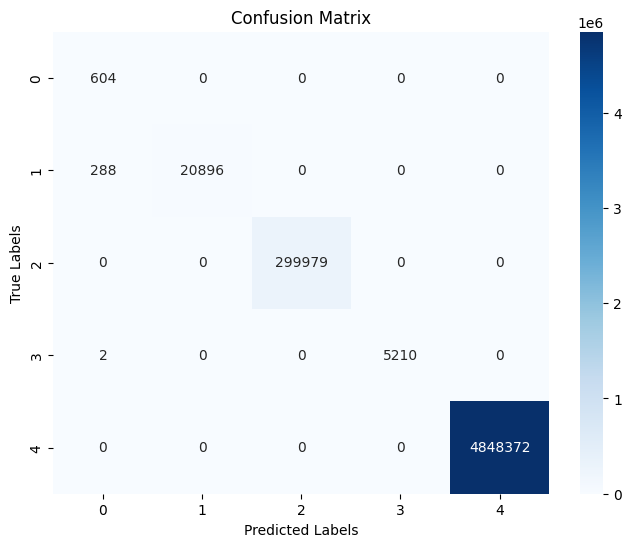

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_felids_dnn_type_glob_model.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_felids_dnn_type_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 4 class classification felids_dnn_type 1st fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_dnn_type 1st fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_dnn_type 1st fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_dnn_type 1st fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_dnn_type 1st fl: {mcc:.4f}")

Accuracy for 4 class classification felids_dnn_type 1st fl: 0.9999
Precision for 4 class classification felids_dnn_type 1st fl: 0.9351
Recall for 4 class classification felids_dnn_type 1st fl: 0.9972
F1 Score for 4 class classification felids_dnn_type 1st fl: 0.9599
MCC for 4 class classification felids_dnn_type 1st fl: 0.9995


2nd fl round for felids dnn type classification

301894/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.9999 - loss: 3.4774e-04
Epoch 1: val_loss improved from inf to 0.00013, saving model to D:/linthoi/FL_models/new/client2/type/client2_felids_dnn_type_2nd_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 6331s 21ms/step - accuracy: 0.9999 - loss: 3.4774e-04 - val_accuracy: 0.9999 - val_loss: 1.3004e-04
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 702s 4ms/step
Accuracy Score: 0.9999319852895002


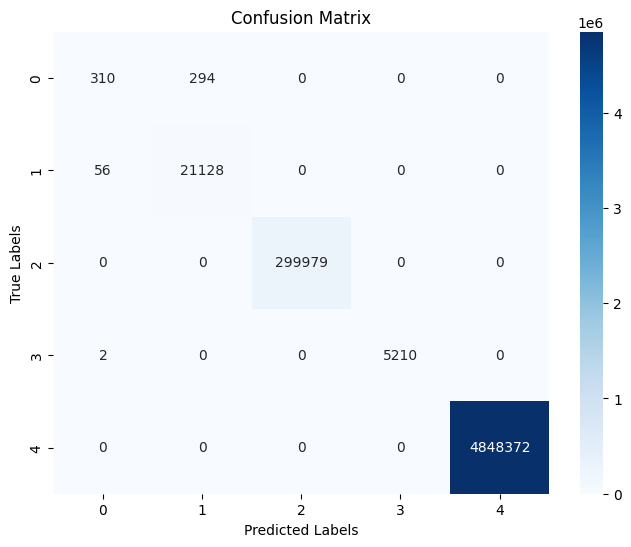

In [10]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_felids_dnn_type_glob_model.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_felids_dnn_type_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [11]:
print(f"Accuracy for 4 class classification felids_dnn_type 2nd fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_dnn_type 2nd fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_dnn_type 2nd fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_dnn_type 2nd fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_dnn_type 2nd fl: {mcc:.4f}")

Accuracy for 4 class classification felids_dnn_type 2nd fl: 0.9999
Precision for 4 class classification felids_dnn_type 2nd fl: 0.9657
Recall for 4 class classification felids_dnn_type 2nd fl: 0.9020
F1 Score for 4 class classification felids_dnn_type 2nd fl: 0.9259
MCC for 4 class classification felids_dnn_type 2nd fl: 0.9994


3rd felids dnn type classification round

301896/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - accuracy: 0.9999 - loss: 3.9517e-04
Epoch 1: val_loss improved from inf to 0.00013, saving model to D:/linthoi/FL_models/new/client2/type/client2_felids_dnn_type_3rd_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 7326s 24ms/step - accuracy: 0.9999 - loss: 3.9517e-04 - val_accuracy: 0.9999 - val_loss: 1.3342e-04
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 761s 5ms/step
Accuracy Score: 0.9999178799660158


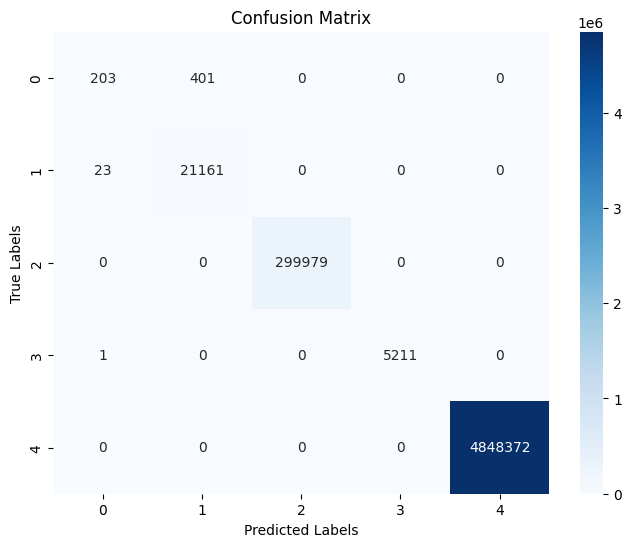

In [12]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_felids_dnn_type_glob_model.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_felids_dnn_type_3rd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [13]:
print(f"Accuracy for 4 class classification felids_dnn_type 3rd fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_dnn_type 3rd fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_dnn_type 3rd fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_dnn_type 3rd fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_dnn_type 3rd fl: {mcc:.4f}")

Accuracy for 4 class classification felids_dnn_type 3rd fl: 0.9999
Precision for 4 class classification felids_dnn_type 3rd fl: 0.9751
Recall for 4 class classification felids_dnn_type 3rd fl: 0.8670
F1 Score for 4 class classification felids_dnn_type 3rd fl: 0.8957
MCC for 4 class classification felids_dnn_type 3rd fl: 0.9993


FELIDS CNN 4 class classification (category) BEFORE FL

301886/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9976 - loss: 0.0104
Epoch 1: val_loss improved from inf to 0.00023, saving model to D:/linthoi/FL_models/new/client2/category/client2_FELIDS_cnn_CATE_bfore_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 1484s 5ms/step - accuracy: 0.9976 - loss: 0.0104 - val_accuracy: 1.0000 - val_loss: 2.3117e-04
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 393s 2ms/step
Accuracy Score: 0.9999857014529063


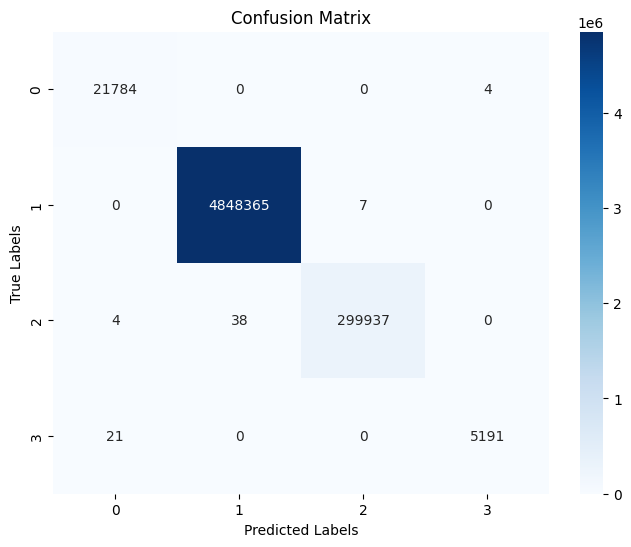

In [6]:

early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_dnn_cate = load_model(r'D:\linthoi\FL_models\new\glob_models\Category_glob_model\firstinitialized\felids_cnn_cate_glob_model.h5')
felids_dnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/category/client2_FELIDS_cnn_CATE_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_dnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_dnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 4 class classification felids_cnn_cate before fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_cnn_cate before fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_cnn_cate before fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_cnn_cate before fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_cnn_cate before fl: {mcc:.4f}")

Accuracy for 4 class classification felids_cnn_cate before fl: 1.0000
Precision for 4 class classification felids_cnn_cate before fl: 0.9995
Recall for 4 class classification felids_cnn_cate before fl: 0.9989
F1 Score for 4 class classification felids_cnn_cate before fl: 0.9992
MCC for 4 class classification felids_cnn_cate before fl: 0.9999


1st fl felids cnn category round

301896/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9995 - loss: 0.0022
Epoch 1: val_loss improved from inf to 0.00130, saving model to D:/linthoi/FL_models/new/client2/category/client2_FELIDS_cnn_CATE_1st_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 9730s 32ms/step - accuracy: 0.9995 - loss: 0.0022 - val_accuracy: 0.9999 - val_loss: 0.0013
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 2208s 14ms/step
Accuracy Score: 0.9999420329171876


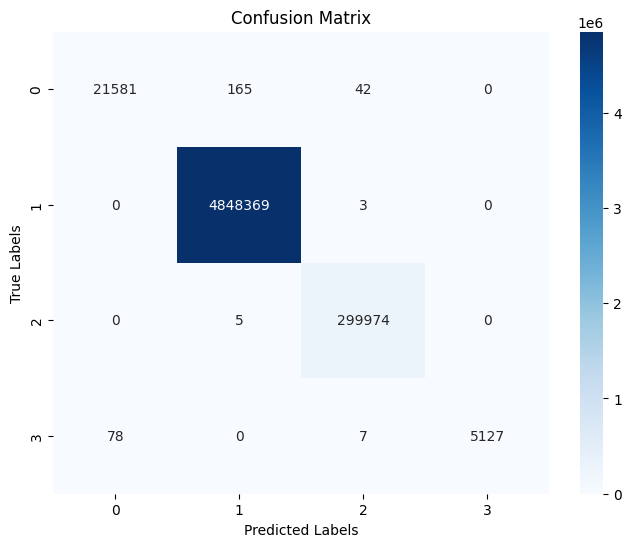

In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/1st_round_felids_cnn_cate_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/category/client2_FELIDS_cnn_CATE_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 4 class classification felids_cnn_cate 1st fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_cnn_cate 1st fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_cnn_cate 1st fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_cnn_cate 1st fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_cnn_cate 1st fl: {mcc:.4f}")

Accuracy for 4 class classification felids_cnn_cate 1st fl: 0.9999
Precision for 4 class classification felids_cnn_cate 1st fl: 0.9990
Recall for 4 class classification felids_cnn_cate 1st fl: 0.9935
F1 Score for 4 class classification felids_cnn_cate 1st fl: 0.9963
MCC for 4 class classification felids_cnn_cate 1st fl: 0.9995


2nd fl round for felids cnn category 

301890/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9999 - loss: 9.0310e-04
Epoch 1: val_loss improved from inf to 0.00011, saving model to D:/linthoi/FL_models/new/client2/category/client2_FELIDS_cnn_CATE_2nd_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 1360s 4ms/step - accuracy: 0.9999 - loss: 9.0310e-04 - val_accuracy: 1.0000 - val_loss: 1.1487e-04
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 411s 3ms/step
Accuracy Score: 0.9999785521793594


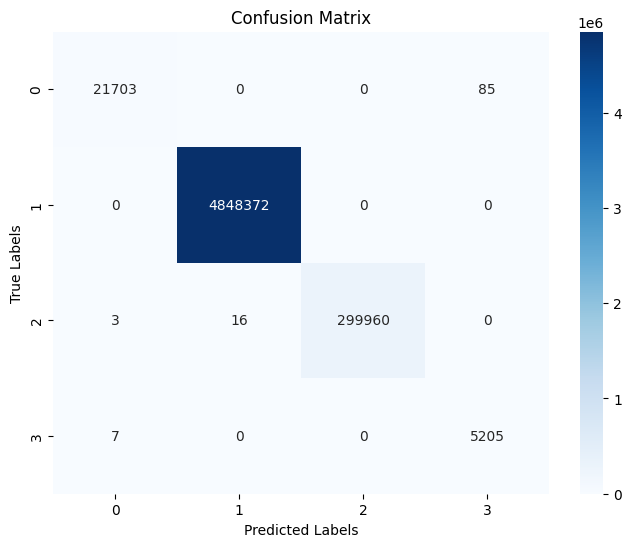

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/2nd_round_felids_cnn_cate_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/category/client2_FELIDS_cnn_CATE_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 4 class classification felids_cnn_cate 2nd fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_cnn_cate 2nd fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_cnn_cate 2nd fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_cnn_cate 2nd fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_cnn_cate 2nd fl: {mcc:.4f}")

Accuracy for 4 class classification felids_cnn_cate 2nd fl: 1.0000
Precision for 4 class classification felids_cnn_cate 2nd fl: 0.9959
Recall for 4 class classification felids_cnn_cate 2nd fl: 0.9987
F1 Score for 4 class classification felids_cnn_cate 2nd fl: 0.9973
MCC for 4 class classification felids_cnn_cate 2nd fl: 0.9998


3rd fl round felids cnn category

301891/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.9999 - loss: 9.6841e-04
Epoch 1: val_loss improved from inf to 0.00009, saving model to D:/linthoi/FL_models/new/client2/category/client2_FELIDS_cnn_CATE_3rd_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 1429s 5ms/step - accuracy: 0.9999 - loss: 9.6841e-04 - val_accuracy: 1.0000 - val_loss: 8.7660e-05
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 389s 2ms/step
Accuracy Score: 0.9999961355278125


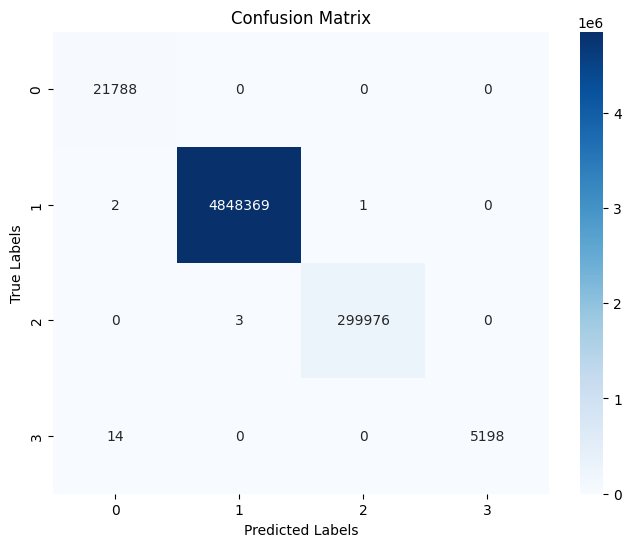

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/updated_models/3rd_round_felids_cnn_cate_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/category/client2_FELIDS_cnn_CATE_3rd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 4 class classification felids_cnn_cate 3rd fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_cnn_cate 3rd fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_cnn_cate 3rd fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_cnn_cate 3rd fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_cnn_cate 3rd fl: {mcc:.4f}")

Accuracy for 4 class classification felids_cnn_cate 3rd fl: 1.0000
Precision for 4 class classification felids_cnn_cate 3rd fl: 0.9998
Recall for 4 class classification felids_cnn_cate 3rd fl: 0.9993
F1 Score for 4 class classification felids_cnn_cate 3rd fl: 0.9996
MCC for 4 class classification felids_cnn_cate 3rd fl: 1.0000


felids cnn type before fl

301894/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.9974 - loss: 0.0120
Epoch 1: val_loss improved from inf to 0.00029, saving model to D:/linthoi/FL_models/new/client2/type/client2_FELIDS_cnn_type_bfore_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 8742s 29ms/step - accuracy: 0.9974 - loss: 0.0120 - val_accuracy: 0.9999 - val_loss: 2.9085e-04
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 1689s 10ms/step
Accuracy Score: 0.999873052088641


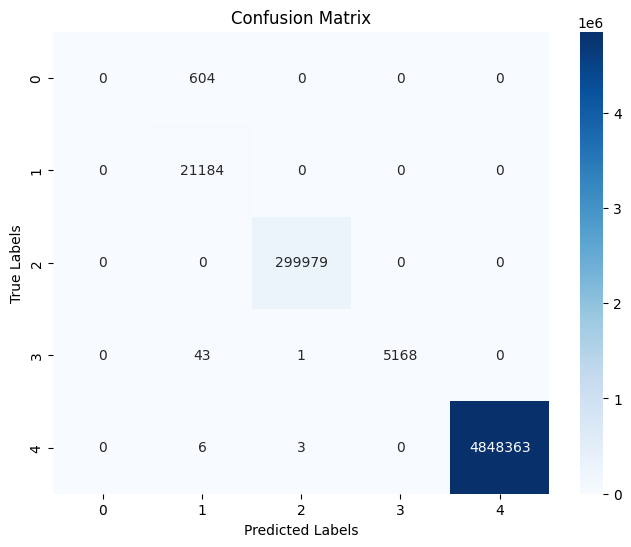

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model(r'D:\linthoi\FL_models\new\glob_models\Type_glob_model\firstinitialized\felids_cnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_FELIDS_cnn_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [15]:
print(f"Accuracy for 5 class classification felids_cnn_type before fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_cnn_type before fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_cnn_type before fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_cnn_type before fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_cnn_type before fl: {mcc:.4f}")

Accuracy for 5 class classification felids_cnn_type before fl: 0.9999
Precision for 5 class classification felids_cnn_type before fl: 0.7940
Recall for 5 class classification felids_cnn_type before fl: 0.7983
F1 Score for 5 class classification felids_cnn_type before fl: 0.7961
MCC for 5 class classification felids_cnn_type before fl: 0.9989


1st fl round for felids cnn type

301893/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.9993 - loss: 0.0027
Epoch 1: val_loss improved from inf to 0.05781, saving model to D:/linthoi/FL_models/new/client2/type/client2_FELIDS_cnn_type_1st_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 1548s 5ms/step - accuracy: 0.9993 - loss: 0.0027 - val_accuracy: 0.9988 - val_loss: 0.0578
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 415s 3ms/step
Accuracy Score: 0.9987828844845499


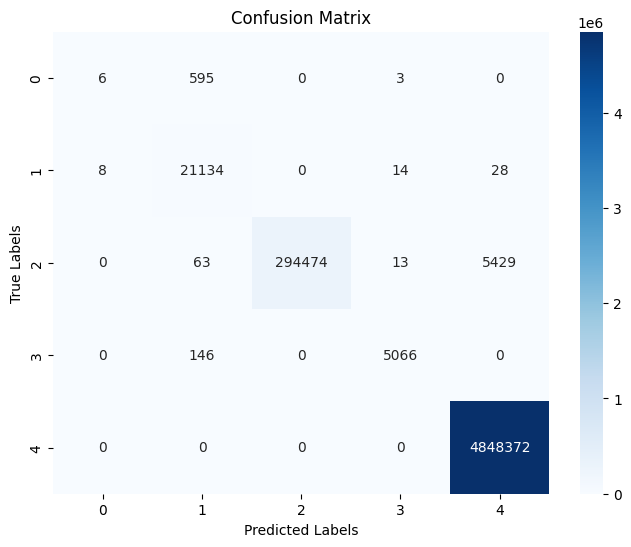

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_felids_cnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_FELIDS_cnn_type_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 5 class classification felids_cnn_type 1st fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_cnn_type 1st fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_cnn_type 1st fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_cnn_type 1st fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_cnn_type 1st fl: {mcc:.4f}")

Accuracy for 5 class classification felids_cnn_type 1st fl: 0.9988
Precision for 5 class classification felids_cnn_type 1st fl: 0.8770
Recall for 5 class classification felids_cnn_type 1st fl: 0.7922
F1 Score for 5 class classification felids_cnn_type 1st fl: 0.7945
MCC for 5 class classification felids_cnn_type 1st fl: 0.9897


2nd fl round felids cnn type

301894/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step - accuracy: 0.9997 - loss: 0.0013
Epoch 1: val_loss improved from inf to 0.00026, saving model to D:/linthoi/FL_models/new/client2/type/client2_FELIDS_cnn_type_2nd_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 8933s 30ms/step - accuracy: 0.9997 - loss: 0.0013 - val_accuracy: 0.9999 - val_loss: 2.6341e-04
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 1874s 12ms/step
Accuracy Score: 0.9998608790012503


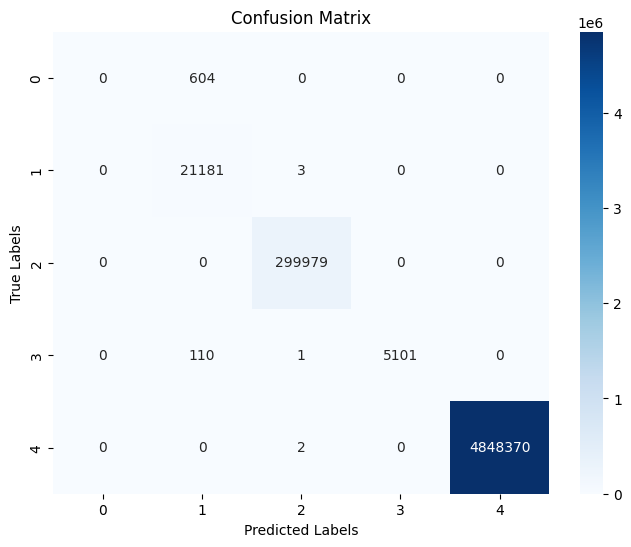

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_felids_cnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_FELIDS_cnn_type_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 5 class classification felids_cnn_type 2nd fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_cnn_type 2nd fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_cnn_type 2nd fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_cnn_type 2nd fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_cnn_type 2nd fl: {mcc:.4f}")

Accuracy for 5 class classification felids_cnn_type 2nd fl: 0.9999
Precision for 5 class classification felids_cnn_type 2nd fl: 0.7935
Recall for 5 class classification felids_cnn_type 2nd fl: 0.7957
F1 Score for 5 class classification felids_cnn_type 2nd fl: 0.7945
MCC for 5 class classification felids_cnn_type 2nd fl: 0.9988


3rd fl felids type classification round

301895/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step - accuracy: 0.9998 - loss: 0.0011
Epoch 1: val_loss improved from inf to 0.00125, saving model to D:/linthoi/FL_models/new/client2/type/client2_FELIDS_cnn_type_3rd_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 9465s 31ms/step - accuracy: 0.9998 - loss: 0.0011 - val_accuracy: 0.9999 - val_loss: 0.0012
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 1803s 11ms/step
Accuracy Score: 0.9998722791942034


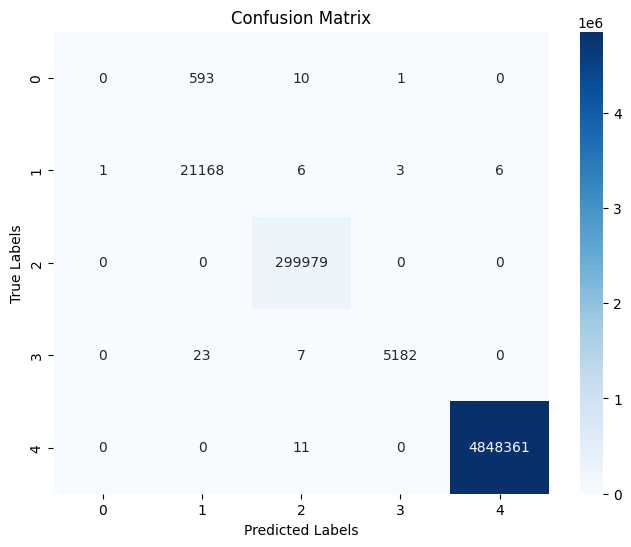

In [10]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_felids_cnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_FELIDS_cnn_type_3rd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [11]:
print(f"Accuracy for 5 class classification felids_cnn_type 3rd fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_cnn_type 3rd fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_cnn_type 3rd fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_cnn_type 3rd fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_cnn_type 3rd fl: {mcc:.4f}")

Accuracy for 5 class classification felids_cnn_type 3rd fl: 0.9999
Precision for 5 class classification felids_cnn_type 3rd fl: 0.7942
Recall for 5 class classification felids_cnn_type 3rd fl: 0.7987
F1 Score for 5 class classification felids_cnn_type 3rd fl: 0.7964
MCC for 5 class classification felids_cnn_type 3rd fl: 0.9989


felids rnn category classification before fl

301896/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step - accuracy: 0.9960 - loss: 0.0222
Epoch 1: val_loss improved from inf to 0.00072, saving model to D:/linthoi/FL_models/new/client2/category/client2_FELIDS_rnn_cate_bfore_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 25589s 85ms/step - accuracy: 0.9960 - loss: 0.0222 - val_accuracy: 1.0000 - val_loss: 7.1800e-04
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 11021s 68ms/step
Accuracy Score: 1.0


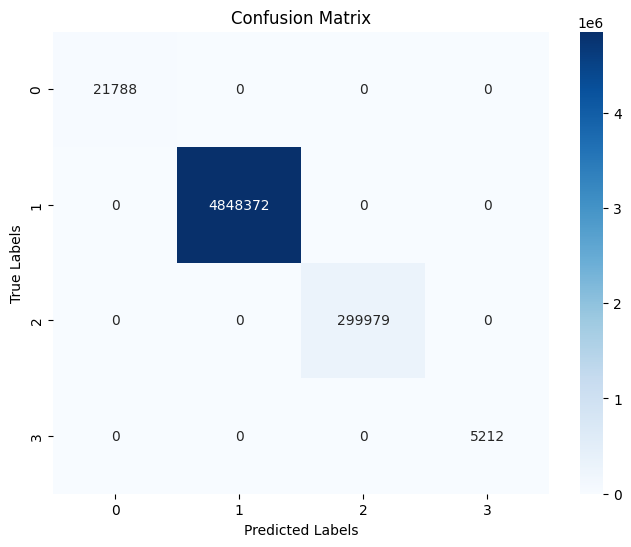

In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Category_glob_model/firstinitialized/felids_RNN_cate.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/category/client2_FELIDS_rnn_cate_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 4 class classification felids_rnn_cate_bfore fl: {accuracy:.4f}")
print(f"Precision for 4 class classification felids_rnn_cate_bfore  fl: {precision:.4f}")
print(f"Recall for 4 class classification felids_rnn_cate_bfore  fl: {recall:.4f}")
print(f"F1 Score for 4 class classification felids_rnn_cate_bfore  fl: {f1:.4f}")
print(f"MCC for 4 class classification felids_rnn_cate_bfore  fl: {mcc:.4f}")

Accuracy for 4 class classification felids_rnn_cate_bfore fl: 1.0000
Precision for 4 class classification felids_rnn_cate_bfore  fl: 1.0000
Recall for 4 class classification felids_rnn_cate_bfore  fl: 1.0000
F1 Score for 4 class classification felids_rnn_cate_bfore  fl: 1.0000
MCC for 4 class classification felids_rnn_cate_bfore  fl: 1.0000


felids rnn type before fl classification

301896/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 76ms/step - accuracy: 0.9953 - loss: 0.0284
Epoch 1: val_loss improved from inf to 0.00054, saving model to D:/linthoi/FL_models/new/client2/type/client2_FELIDS_rnn_type_bfore_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 25603s 85ms/step - accuracy: 0.9953 - loss: 0.0284 - val_accuracy: 0.9999 - val_loss: 5.4018e-04
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 11133s 69ms/step
Accuracy Score: 0.9998832929399378


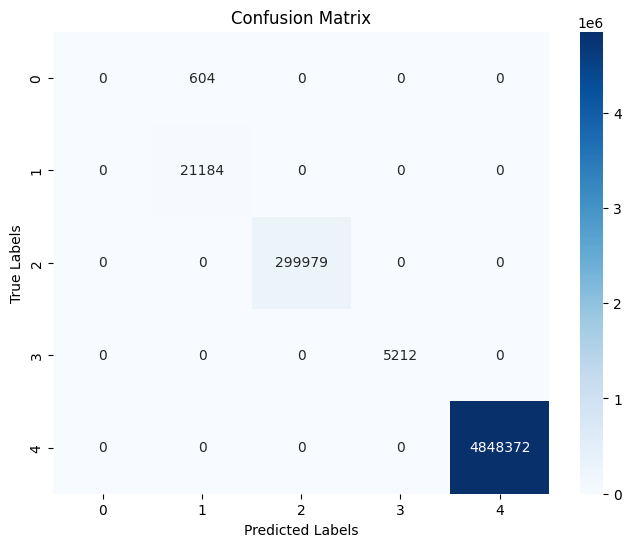

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/firstinitialized/felids_RNN_type.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_FELIDS_rnn_type_bfore_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 5 class classification felids_rnn_type_bfore fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_rnn_type_bfore  fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_rnn_type_bfore  fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_rnn_type_bfore  fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_rnn_type_bfore  fl: {mcc:.4f}")

Accuracy for 5 class classification felids_rnn_type_bfore fl: 0.9999
Precision for 5 class classification felids_rnn_type_bfore  fl: 0.7945
Recall for 5 class classification felids_rnn_type_bfore  fl: 0.8000
F1 Score for 5 class classification felids_rnn_type_bfore  fl: 0.7972
MCC for 5 class classification felids_rnn_type_bfore  fl: 0.9990


1st fl round felids type classification

301896/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step - accuracy: 0.9980 - loss: 0.0109
Epoch 1: val_loss improved from inf to 0.00053, saving model to D:/linthoi/FL_models/new/client2/type/client2_FELIDS_rnn_type_1st_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 28693s 95ms/step - accuracy: 0.9980 - loss: 0.0109 - val_accuracy: 0.9999 - val_loss: 5.3426e-04
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 11410s 71ms/step
Accuracy Score: 0.9998832929399378


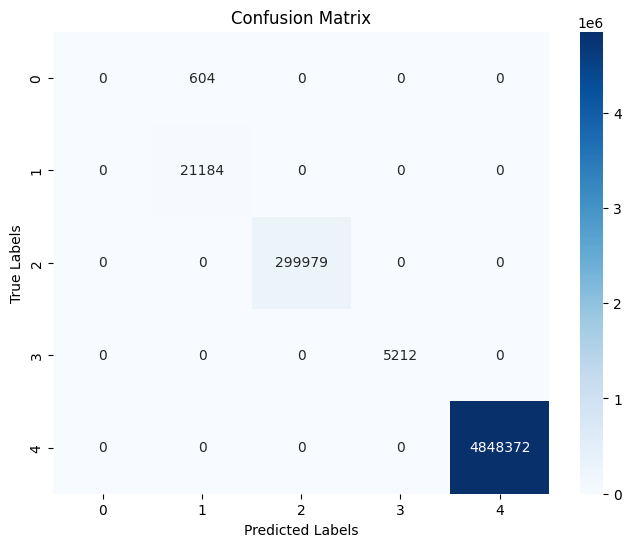

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/1st_round_felids_rnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_FELIDS_rnn_type_1st_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 5 class classification felids_rnn_type_1st fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_rnn_type_1st  fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_rnn_type_1st  fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_rnn_type_1st  fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_rnn_type_1st  fl: {mcc:.4f}")

Accuracy for 5 class classification felids_rnn_type_1st fl: 0.9999
Precision for 5 class classification felids_rnn_type_1st  fl: 0.7945
Recall for 5 class classification felids_rnn_type_1st  fl: 0.8000
F1 Score for 5 class classification felids_rnn_type_1st  fl: 0.7972
MCC for 5 class classification felids_rnn_type_1st  fl: 0.9990


felids rnn type 2nd fl round

301896/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 252ms/step - accuracy: 0.9987 - loss: 0.0057
Epoch 1: val_loss improved from inf to 0.00049, saving model to D:/linthoi/FL_models/new/client2/type/client2_FELIDS_rnn_type_2nd_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 81453s 270ms/step - accuracy: 0.9987 - loss: 0.0057 - val_accuracy: 0.9999 - val_loss: 4.8533e-04
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 10745s 66ms/step
Accuracy Score: 0.9998832929399378


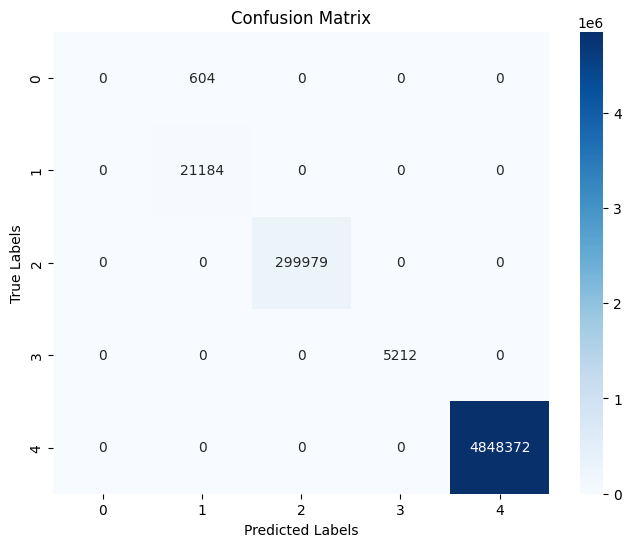

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [8]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/2nd_round_felids_rnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_FELIDS_rnn_type_2nd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [9]:
print(f"Accuracy for 5 class classification felids_rnn_type_2nd fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_rnn_type_2nd  fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_rnn_type_2nd  fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_rnn_type_2nd  fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_rnn_type_2nd  fl: {mcc:.4f}")

Accuracy for 5 class classification felids_rnn_type_2nd fl: 0.9999
Precision for 5 class classification felids_rnn_type_2nd  fl: 0.7945
Recall for 5 class classification felids_rnn_type_2nd  fl: 0.8000
F1 Score for 5 class classification felids_rnn_type_2nd  fl: 0.7972
MCC for 5 class classification felids_rnn_type_2nd  fl: 0.9990


3rd felids fl rnn type classification round

301896/301896 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step - accuracy: 0.9997 - loss: 0.0013
Epoch 1: val_loss improved from inf to 0.00066, saving model to D:/linthoi/FL_models/new/client2/type/client2_FELIDS_rnn_type_3rd_FL_weight.keras
301896/301896 ━━━━━━━━━━━━━━━━━━━━ 28185s 93ms/step - accuracy: 0.9997 - loss: 0.0013 - val_accuracy: 0.9999 - val_loss: 6.6399e-04
Restoring model weights from the end of the best epoch: 1.
161730/161730 ━━━━━━━━━━━━━━━━━━━━ 12327s 76ms/step
Accuracy Score: 0.9998832929399378


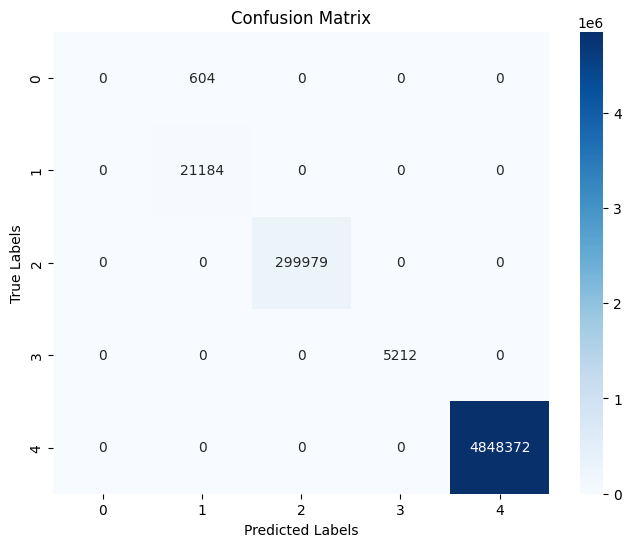

c:\Users\ranja\miniconda3\Lib\site-packages\sklearn\metrics\_classification.py:1517: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [6]:
early_stopping = tf.keras.callbacks.EarlyStopping(monitor = 'val_loss', patience = 5, verbose = 1, restore_best_weights=True)
felids_cnn_cate = load_model('D:/linthoi/FL_models/new/glob_models/Type_glob_model/updated_models/3rd_round_felids_rnn_type_glob_model.h5')
felids_cnn_cate.compile(optimizer='adam', loss='sparse_categorical_crossentropy', metrics=['accuracy'])
checkpoint_callback = ModelCheckpoint('D:/linthoi/FL_models/new/client2/type/client2_FELIDS_rnn_type_3rd_FL_weight.keras', monitor='val_loss', save_best_only=True, mode='min', verbose=1)
felids_cnn_cate.fit(X1_train, y1_train, epochs=1, batch_size=32, validation_split=0.2, callbacks=[checkpoint_callback, early_stopping])
y1_pred = felids_cnn_cate.predict(X1_test) 
y1_pred_labels = np.argmax(y1_pred, axis=1)
accuracy = accuracy_score(y1_test, y1_pred_labels)
print(f"Accuracy Score: {accuracy}")

# Generate the confusion matrix

conf_matrix = confusion_matrix(y1_test, y1_pred_labels)

# Visualize the confusion matrix using a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues', xticklabels=np.unique(y1_test), yticklabels=np.unique(y1_test))
plt.xlabel('Predicted Labels')
plt.ylabel('True Labels')
plt.title('Confusion Matrix')
plt.show()
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, matthews_corrcoef
accuracy = accuracy_score(y1_test, y1_pred_labels)

# Compute precision
precision = precision_score(y1_test, y1_pred_labels, average='macro')

# Compute recall
recall = recall_score(y1_test, y1_pred_labels, average='macro')

# Compute F1 score
f1 = f1_score(y1_test, y1_pred_labels, average='macro')

# Compute Matthews correlation coefficient (MCC)
mcc = matthews_corrcoef(y1_test, y1_pred_labels)


In [7]:
print(f"Accuracy for 5 class classification felids_rnn_type_3rd fl: {accuracy:.4f}")
print(f"Precision for 5 class classification felids_rnn_type_3rd  fl: {precision:.4f}")
print(f"Recall for 5 class classification felids_rnn_type_3rd  fl: {recall:.4f}")
print(f"F1 Score for 5 class classification felids_rnn_type_3rd  fl: {f1:.4f}")
print(f"MCC for 5 class classification felids_rnn_type_3rd  fl: {mcc:.4f}")

Accuracy for 5 class classification felids_rnn_type_3rd fl: 0.9999
Precision for 5 class classification felids_rnn_type_3rd  fl: 0.7945
Recall for 5 class classification felids_rnn_type_3rd  fl: 0.8000
F1 Score for 5 class classification felids_rnn_type_3rd  fl: 0.7972
MCC for 5 class classification felids_rnn_type_3rd  fl: 0.9990
